In [1]:
%matplotlib inline

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import scipy.io.wavfile
from scipy.fftpack import fft, fftfreq

# Probability and Combinatorics Exercise
## Probabilistic Events. Combinatorics and Counting. Distributions

### Problem 1. Exploring Distribution Parameters
A good idea to visualize and explore the parameters of various distributions is just to plot them.

We can do this in either one of two ways:
1. Draw (generate) many random variables which follow that distribution. Plot their histogram
2. Write the distribution function directly and plot it

Either of these will work but the second approach will give us better looking results. [`scipy.stats`](https://docs.scipy.org/doc/scipy-0.19.1/reference/stats.html) has a lot of built-in distributions that we can use. Each of them has its own use cases.

It's very important that we plot discrete and continuous distributions in different ways. **We must not make discrete distributions look continuous**. That is, discrete distributions are only defined for integer number of trials: $n \in \mathbb{N}$.

Let's plot the binomial and Gaussian distributions.

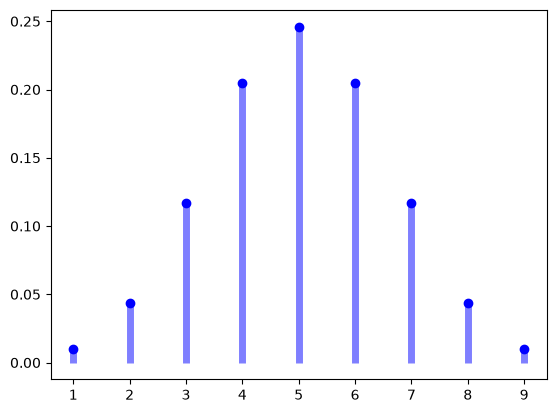

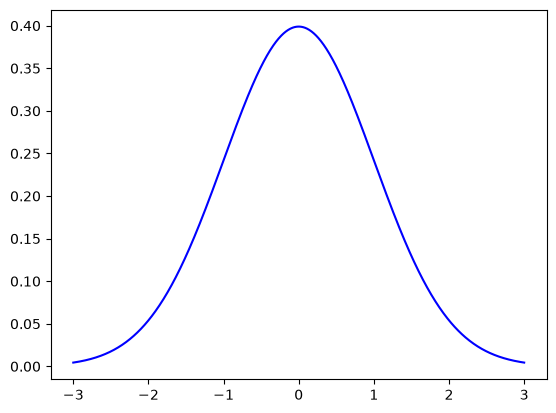

In [3]:
def plot_binomial_distribution(x, n, p):
    """
    Plots the binomial distribution with parameters n and p. The parameter x specifies the values
    where the function is evaluated at
    """
    binomial = scipy.stats.binom.pmf(x, n, p)
    plt.scatter(x, binomial, color = "blue")
    plt.vlines(x, 0, binomial, color = "blue", linewidth = 5, alpha = 0.5)
    plt.show()
    
def plot_gaussian_distribution(mu, sigma, x):
    """
    Plots the Gaussian distribution with parameters mu and sigma. The parameter x specifies 
    the values where the function is evaluated at
    """
    gaussian = scipy.stats.norm.pdf(x, loc = mu, scale = sigma)
    plt.plot(x, gaussian, color = "blue")
    plt.show()
    
x_binomial = np.arange(1, 10)
plot_binomial_distribution(x_binomial, 10, 0.5)

x_gaussian = np.linspace(-3, 3, 1000)
plot_gaussian_distribution(0, 1, x_gaussian)

These look similar. That's with a good reason: the Gaussian distribution is a generalization of the binomial distribution as $n \rightarrow \infty$.

What do these parameters specify exactly? Let's find out. 

Take the binomial distribution. Keep $p = 0.5$ and change $n$. Plot several values of $n$ in the same plot, with different colors. **What values to choose?** Remember that $n$ was the number of experiments, so it should be an integer $\ge 1$.

Now keep $n$ at some reasonable value (a number between 10 and 30 should be good) and change $p$. $p$ is a probability so its values must be between 0 and 1.

What can you conclude? How does the function shape change? When is it symmetrical and when it is not?

Perform the same kind of operations on $\mu$ and $\sigma$ with the Gaussian distribution. What do these parameters represent?

If you get stuck, try to find what the distribution functions should look like on the Internet.

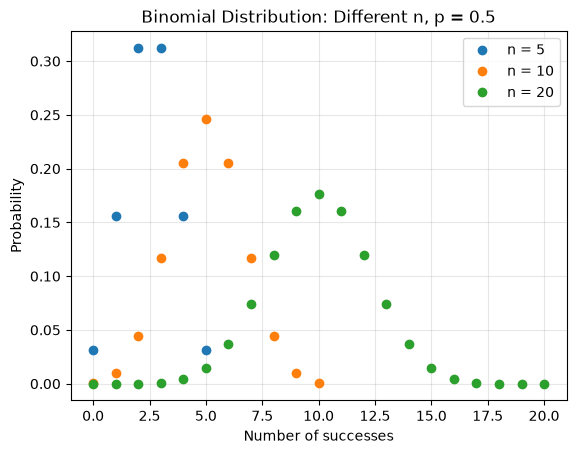

In [4]:
# Write your code here
# Binomial distribution: change n, keep p = 0.5

p = 0.5

for n in [5, 10, 20]:
    x = np.arange(0, n + 1)
    probabilities = scipy.stats.binom.pmf(x, n, p)

    plt.plot(
        x,
        probabilities,
        marker="o",
        linestyle="None",
        label=f"n = {n}"
    )

plt.title("Binomial Distribution: Different n, p = 0.5")
plt.xlabel("Number of successes")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

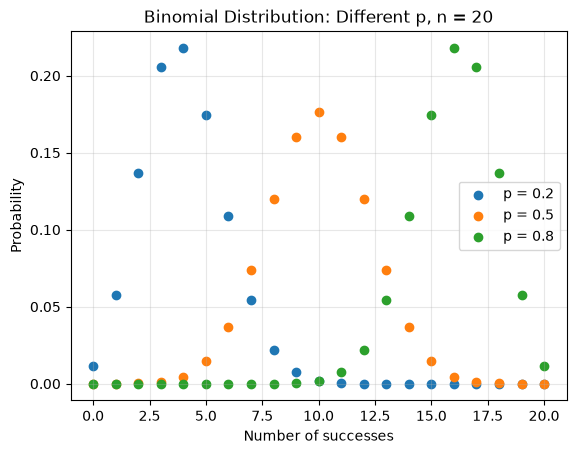

In [5]:
# Binomial distribution: change p, keep n = 20

n = 20
x = np.arange(0, n + 1)

for p in [0.2, 0.5, 0.8]:
    probabilities = scipy.stats.binom.pmf(x, n, p)

    plt.scatter(
        x,
        probabilities,
        label=f"p = {p}"
    )

plt.title("Binomial Distribution: Different p, n = 20")
plt.xlabel("Number of successes")
plt.ylabel("Probability")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Binomial Distribution — Experimental Results and Conclusions

Experiment 1: Changing the number of trials (n)

When the probability of success is fixed at p = 0.5, increasing the number of trials shifts the center of the distribution toward larger values and increases its absolute spread. The maximum probability of an individual outcome decreases.

The distribution remains symmetric around its expected value:

[
E[X] = np
]

Experiment 2: Changing the probability of success (p)

When n = 20 is fixed, changing p affects both the position and the shape of the distribution.

At p = 0.2, the distribution is right-skewed.

At p = 0.5, the distribution is symmetric.

At p = 0.8, the distribution is left-skewed.

The distributions for p = 0.2 and p = 0.8 are mirror images.

Conclusion

The binomial distribution depends on two parameters: the number of independent trials (n) and the probability of success (p). The expected number of successes is np, and the variance is np(1 − p).

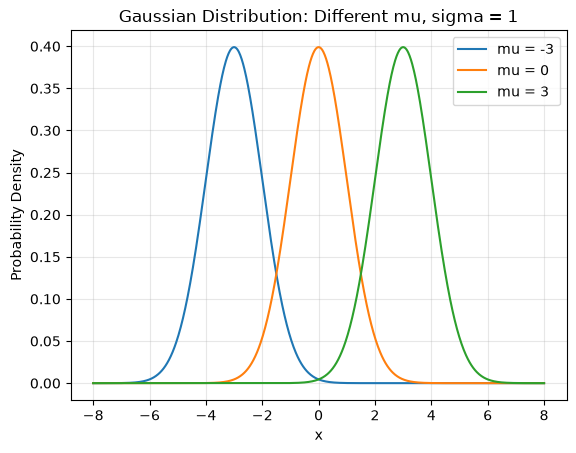

In [6]:
# Gaussian distribution: change mu, keep sigma = 1

x = np.linspace(-8, 8, 1000)
sigma = 1

for mu in [-3, 0, 3]:
    gaussian = scipy.stats.norm.pdf(
        x,
        loc=mu,
        scale=sigma
    )

    plt.plot(
        x,
        gaussian,
        label=f"mu = {mu}"
    )

plt.title("Gaussian Distribution: Different mu, sigma = 1")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

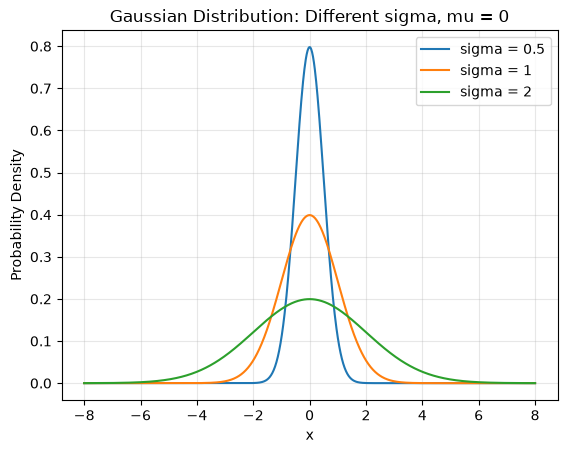

In [7]:
# Gaussian distribution: change sigma, keep mu = 0

x = np.linspace(-8, 8, 1000)
mu = 0

for sigma in [0.5, 1, 2]:
    gaussian = scipy.stats.norm.pdf(
        x,
        loc=mu,
        scale=sigma
    )

    plt.plot(
        x,
        gaussian,
        label=f"sigma = {sigma}"
    )

plt.title("Gaussian Distribution: Different sigma, mu = 0")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Problem 2. Central Limit Theorem

The [**Central Limit Theorem**](https://en.wikipedia.org/wiki/Central_limit_theorem) states that, under suitable conditions, the distribution of sums of independent random variables approaches a normal distribution as the number of variables increases.

Consider the following functions:

$$
f(x) = 1
$$

$$
f(x) = 2x
$$

$$
f(x) = 3x^2
$$

$$
f(x) = 4|x - 0.5|
$$

$$
f(x) = 2 - 4|x - 0.5|
$$

For each function $f$:

1. Generate 2000 values of $x$ between 0 and 1.
2. Calculate $f(x)$ and plot the original function.
3. Perform 1000 experiments:
   - Generate 25 random values between 0 and 1 using `np.random.rand(25)`.
   - Calculate $y = f(x)$.
   - Sum the 25 values of $y$.
   - Store the resulting sum.
4. Plot the distribution of the 1000 sums.

#### Questions

- What do you observe?
- Can you experiment with combinations of functions?
- When is the normal distribution a good approximation of the actual distribution?
- What happens when the function is constant?

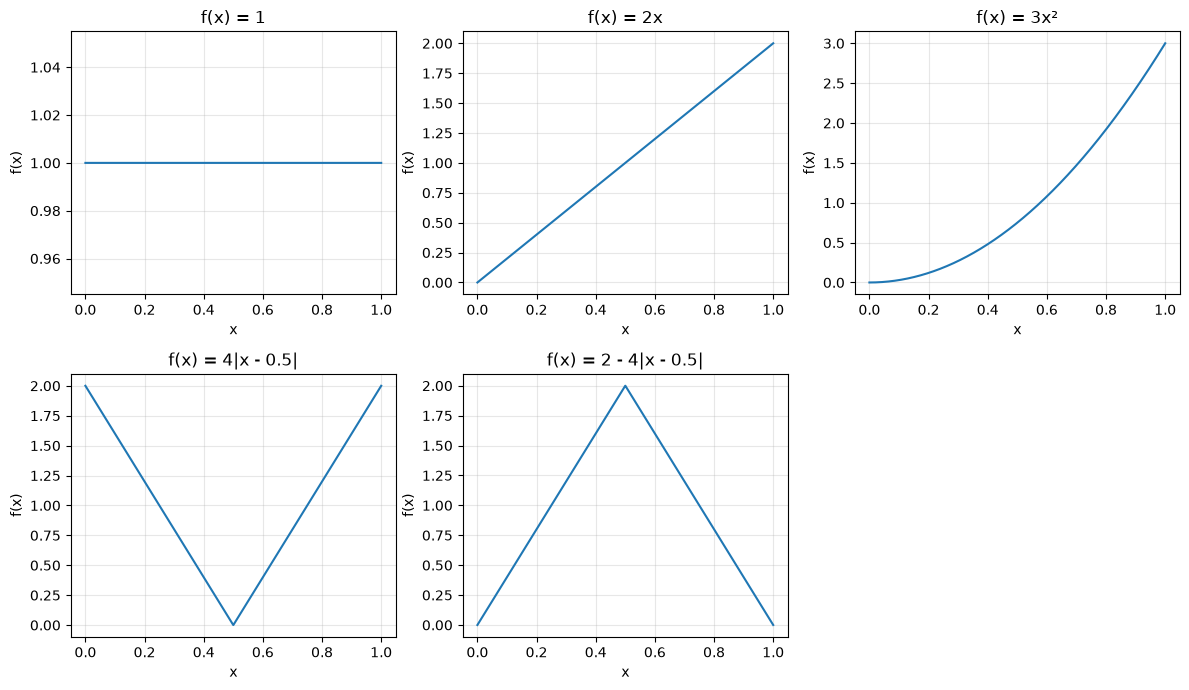

In [8]:
# Write your code here
# Problem 2: Central Limit Theorem
# Step 1: Plot the five original functions

x = np.linspace(0, 1, 2000)

functions = [
    ("f(x) = 1", np.ones_like(x)),
    ("f(x) = 2x", 2 * x),
    ("f(x) = 3x²", 3 * x ** 2),
    ("f(x) = 4|x - 0.5|", 4 * np.abs(x - 0.5)),
    ("f(x) = 2 - 4|x - 0.5|",
     2 - 4 * np.abs(x - 0.5))
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (name, y) in zip(axes.flat, functions):
    ax.plot(x, y)
    ax.set_title(name)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(alpha=0.3)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

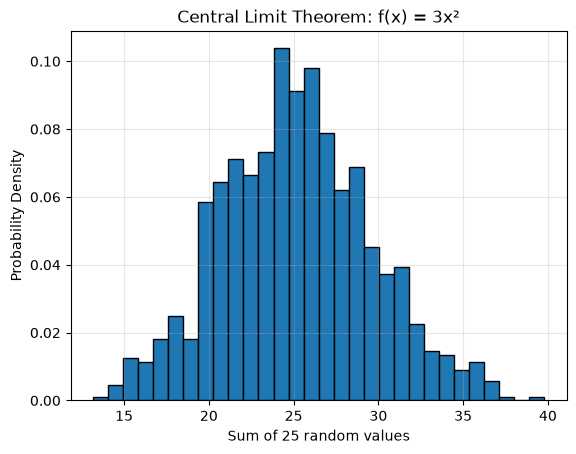

In [9]:
# Central Limit Theorem experiment
# Function: f(x) = 3x^2

sums = []
for experiment in range(1000):
    x = np.random.rand(25)
    y = 3 * x ** 2

    total = np.sum(y)
    sums.append(total)

plt.hist(sums, bins=30, density=True, edgecolor="black")

plt.title("Central Limit Theorem: f(x) = 3x²")
plt.xlabel("Sum of 25 random values")
plt.ylabel("Probability Density")
plt.grid(alpha=0.3)
plt.show()

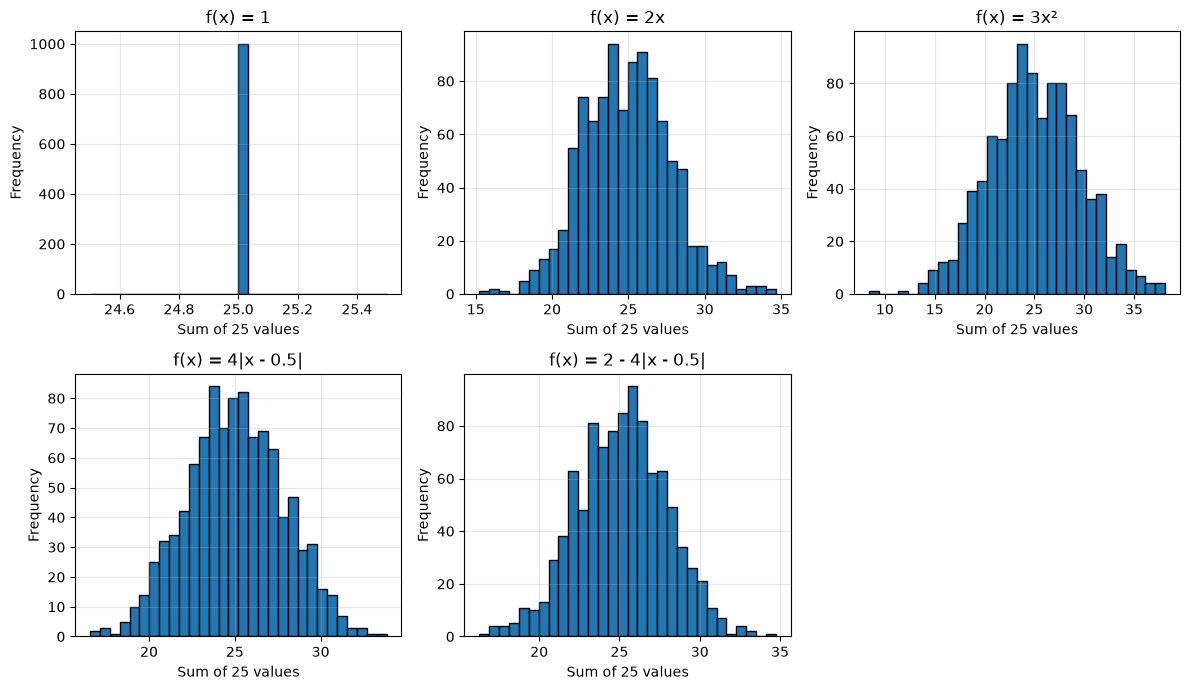

In [10]:
# Central Limit Theorem: Compare all five functions

functions = [
    ("f(x) = 1", lambda x: np.ones_like(x)),
    ("f(x) = 2x", lambda x: 2 * x),
    ("f(x) = 3x²", lambda x: 3 * x ** 2),
    ("f(x) = 4|x - 0.5|", lambda x: 4 * np.abs(x - 0.5)),
    ("f(x) = 2 - 4|x - 0.5|",
     lambda x: 2 - 4 * np.abs(x - 0.5))
]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, (name, func) in zip(axes.flat, functions):
    sums = []

    for _ in range(1000):
        x = np.random.rand(25)
        y = func(x)
        sums.append(np.sum(y))

    ax.hist(sums, bins=30, edgecolor="black")
    ax.set_title(name)
    ax.set_xlabel("Sum of 25 values")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

### Central Limit Theorem — Experimental Results and Conclusions

#### 1. Experimental Setup

For each of the five functions, I performed **1000 independent experiments**.

In each experiment:

1. Generate 25 random values from the uniform distribution on [0, 1].
2. Apply the selected function to all 25 values.
3. Calculate the sum of the resulting values.
4. Store the sum for statistical analysis.

The functions are:

$$
f_1(x) = 1
$$

$$
f_2(x) = 2x
$$

$$
f_3(x) = 3x^2
$$

$$
f_4(x) = 4|x - 0.5|
$$

$$
f_5(x) = 2 - 4|x - 0.5|
$$

#### 2. Experimental Observations

- **Function 1:** All sums are exactly 25 because the function is constant.
- **Function 2:** The sums form an approximately bell-shaped distribution.
- **Function 3:** The sums also approach a normal distribution.
- **Function 4:** The sums show an approximately normal distribution.
- **Function 5:** The sums show an approximately normal distribution.

#### 3. Mathematical Interpretation

The **Central Limit Theorem (CLT)** states that, under suitable conditions, the distribution of standardized sums of independent, identically distributed random variables with finite, nonzero variance approaches the standard normal distribution as the number of variables increases.

The sum of 25 transformed random variables is:

$$
S_{25} = \sum_{i=1}^{25} f(X_i)
$$

For all five functions in this experiment:

$$
E[f(X)] = 1
$$

Therefore:

$$
E[S_{25}] = 25 \cdot 1 = 25
$$

The standardized sum is:

$$
Z_n = \frac{S_n - n\mu}{\sigma\sqrt{n}}
$$

For nonzero variance, as the number of summed variables increases:

$$
Z_n \xrightarrow{d} N(0,1)
$$

The constant function has zero variance, so its sums remain exactly 25 and do not form a normal distribution.

#### 4. Scientific Conclusion

The experiment illustrates that sums of independent random variables can approach a normal distribution even when the original functions have different shapes.

The approximation generally improves as the number of summed variables increases.

The constant function demonstrates an important limitation: the standard non-degenerate form of the Central Limit Theorem requires positive, finite variance.

**Result:** The experimental histograms are consistent with the Central Limit Theorem.

### Problem 3. Birthday Paradox
How many people do we need to have in a room, so that the probability of two people sharing a birthday is $p(A) > 0,5$?

We suppose no leap years, so a year has 365 days. We could expect that we need about $365/2=182$ people. Well, the truth is a bit different.

#### Solution
**Random variable:** $A$: probability that two people share a birthday.

It's sometimes easier to work with the complementary variable: $\bar{A}$ - probability that **no people** share a birthday. 

Let's suppose we have $r$ people in the room. Of course, if $r = 1$, e.g. only one person, the probability is $1$ (there's no one to share a birthday with). If $r >= 365$, the probability must be 1 (by the so-called [pigeonhole principle](https://en.wikipedia.org/wiki/Pigeonhole_principle): if we have 366 people and 365 days, there's at least one day with a pair of people).

Order the people 1 to $r$. Every person's birthday is independent, so that means 365 days for the first, 365 days for the second, and so on: $365^r$ birthday possibilities in total.

We want no duplications of birthdays. The first person has 365 days to choose from, the second has 364, and so on. The $r$th person has $365-r+1$ days to choose from. Total: $365.364.363.\cdots.(365 - r + 1)$

The probability that no people share the same birthday is the fraction of all non-shared birthdays to all possible birthdays:
$$ p(\bar{A})=\frac{365.364.363.\cdots.(365 - r + 1)}{365^r} $$

We're interested in $A$, not $\bar{A}$ and we know that these are complementary, so their probabilities add up to 1
$$p(A) = 1 - p(\bar{A})$$

Write a function which plots the probability of $r$ people sharing a birthday. Remember this is a discrete distribution and should be plotted like so.

22 people: 0.4756953076625503
23 people: 0.5072972343239857
30 people: 0.7063162427192688


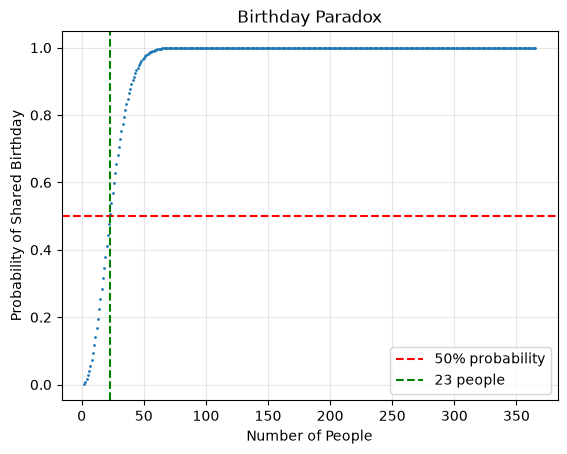

In [11]:
def calculate_birthday_probability(r):
    """
    Return the probability that at least two out of r people
    share a birthday, assuming 365 equally likely dates.
    """
    if r < 2:
        return 0.0

    if r > 365:
        return 1.0

    probability_no_match = 1.0

    for i in range(r):
        probability_no_match *= (365 - i) / 365

    return 1 - probability_no_match


# Test the function
print("22 people:", calculate_birthday_probability(22))
print("23 people:", calculate_birthday_probability(23))
print("30 people:", calculate_birthday_probability(30))

people = np.arange(2, 366)

people = np.arange(2, 366)

probabilities = [
    calculate_birthday_probability(r)
    for r in people
]
plt.plot(people, probabilities, linestyle="None", marker=".", markersize=2)
plt.axhline(0.5, color="red", linestyle="--", label="50% probability")
plt.axvline(23, color="green", linestyle="--", label="23 people")

plt.title("Birthday Paradox")
plt.xlabel("Number of People")
plt.ylabel("Probability of Shared Birthday")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Birthday Paradox — Experimental Results and Conclusion

**Research question:** How many people are needed in a room for the probability of at least two people sharing a birthday to exceed 50%?

**Assumptions:**
- A year contains 365 days.
- Birthdays are independent.
- All dates are equally likely.

The probability that all birthdays are different is:

$$
P(\overline{A}) =
\prod_{i=0}^{r-1}\frac{365-i}{365}
$$

Therefore, the probability of at least one shared birthday is:

$$
P(A)=1-P(\overline{A})
$$

**Experimental results:**

- 22 people: 47.57%
- 23 people: 50.73%
- 30 people: 70.63%

The number of distinct pairs among 23 people is:

$$
\binom{23}{2}=\frac{23\cdot22}{2}=253
$$

**Conclusion:**

The probability of at least two people sharing a birthday first exceeds 50% when there are **23 people** in the room.

This result seems surprising because we often compare the number of people with the 365 possible birthdays. However, the number of possible pairs grows quadratically with the number of people.

The experiment demonstrates how combinatorics and complementary probabilities can be used to calculate the likelihood of collisions.

At how many people do you see a transition from $p(A) < 0,5$ to $p(A) > 0,5$?

**Spoiler alert:** It's 23 people.

Why so few? We're comparing everyone's birthday against everyone else's. We should **NOT** count the number of people, but the number of comparisons. In a room of 23 people, there are 252 total comparisons.

In general, we could get a 50% chance of match using $\sqrt{n}$ people in $n$ days.

### Answer — Birthday Paradox

The probability of at least two people sharing a birthday first exceeds 50% at **23 people**.

- For 22 people: P(A) ≈ 0.4757
- For 23 people: P(A) ≈ 0.5073

The number of distinct pairs among 23 people is:

$$
\binom{23}{2} = \frac{23 \cdot 22}{2} = 253
$$

The number of possible pairs grows quadratically with the number of people.

For a space of $n$ equally likely outcomes, the number of random selections needed for approximately a 50% collision probability is:

$$
r \approx \sqrt{2n\ln 2}
$$

For 365 possible birthdays:

$$
r \approx 22.49
$$

**Conclusion:** The birthday paradox demonstrates how quickly collision probabilities increase as the number of possible pairs grows.

## * Breaking Cryptography: Birthday Attack
We already saw that if we have $n$ days in one year, it takes about $\sqrt{n}$ people to have a 50% chance of two people sharing a birthday. This is used in cryptography for the so-called **birthday attack**.

Let's first introduce **hashing functions**. A hashing function is a function which takes text (bits) of any length and  **returns a fixed number of bits**. There are many such functions. Some of them are completely insecure and **ARE NOT** used in cryptography. They're useful for other purposes, such as hash tables.

Important properties of hashing functions:
1. The output will have a fixed length, no matter whether the input is an empty string, one character, a full sentence, a full book or the entire history of mankind
2. A concrete input will always produce the same output

One such hashing function is **MD5**. It produces 128-bit hashes (32 hexadecimal symbols). This means that it takes the space of all possible texts and converts it to $2^{128} \approx 3.10^{38}$ possible hashes. Since the inputs are much more, by the pigeonhole principle, we can expect that many inputs will produce the same output. This is called a **hashing collision**.

The birthday paradox tells us that using $\sqrt{n} = 2^{64} \approx 2.10^{19}$ hashes, we have a 50% probability of collision. This is still a very large number but compare it to $3.10^{38}$ - the difference is immense.

You can see what these numbers mean in terms of CPU speed [here](https://blog.codinghorror.com/speed-hashing/).

There are other algorithms which are even faster. The fastest one returns about $2^{18}$ hashes before it finds a collision.

Another clever attack is using **rainbow tables**. These are massive dictionaries of precomputed hashes. So, for example, if the input is `password123`, its MD5 hash is `482c811da5d5b4bc6d497ffa98491e38`. Every time an algorithm sees this hash, it can convert it to its input. 

Rainbow tables work because humans are more predictable than algorithms. When implementing any cryptography, remember that **humans are always the weakest factor of any cryptographic system**.

**Optional:** Write a function that finds collisions in **MD5** or **SHA1**. See [this](https://www.mscs.dal.ca/~selinger/md5collision/) demo for a good example, or [this StackOverflow post](https://crypto.stackexchange.com/questions/1434/are-there-two-known-strings-which-have-the-same-md5-hash-value) for more examples.

In [12]:
# Write your code here
import hashlib

text1 = "Hello"
text2 = "Hello!"
text3 = "Hello"

hash1 = hashlib.md5(text1.encode()).hexdigest()
hash2 = hashlib.md5(text2.encode()).hexdigest()
hash3 = hashlib.md5(text3.encode()).hexdigest()

print("Hash 1:", hash1)
print("Hash 2:", hash2)
print("Hash 3:", hash3)

print("Same input, same hash:", hash1 == hash3)
print("Different input, same hash:", hash1 == hash2)

Hash 1: 8b1a9953c4611296a827abf8c47804d7
Hash 2: 952d2c56d0485958336747bcdd98590d
Hash 3: 8b1a9953c4611296a827abf8c47804d7
Same input, same hash: True
Different input, same hash: False


In [13]:
import hashlib

seen_hashes = {}

for i in range(10000):
    text = f"message_{i}"
    short_hash = hashlib.md5(text.encode()).hexdigest()[:4]

    if short_hash in seen_hashes:
        print("Collision found!")
        print("First message:", seen_hashes[short_hash])
        print("Second message:", text)
        print("Shared short hash:", short_hash)
        print("Messages tested:", i + 1)
        break

    seen_hashes[short_hash] = text
else:
    print("No collision found.")

Collision found!
First message: message_253
Second message: message_703
Shared short hash: 1c53
Messages tested: 704


### Birthday Attack — Experimental Results and Conclusion

#### Experimental Setup

I used the MD5 hashing algorithm and kept only the first four hexadecimal characters of each hash.

This produces a truncated 16-bit hash with:

$$
N = 2^{16} = 65536
$$

possible values.

I generated messages sequentially and searched for two different messages with the same truncated hash.

#### Experimental Results

A collision was found:

- First message: `message_253`
- Second message: `message_703`
- Shared truncated hash: `1c53`
- Number of messages tested: **704**

The approximate number of independent, uniformly distributed hashes needed for a 50% collision probability is:

$$
r \approx \sqrt{2N\ln 2}
$$

For a 16-bit hash:

$$
r \approx 301
$$

#### Scientific Conclusion

The experiment demonstrates a collision in a truncated hash function.

Although the hash space contains 65,536 possible values, a collision was found after testing only 704 messages.

The birthday paradox explains why collisions can occur after far fewer attempts than the total number of possible hash values.

The theoretical threshold is probabilistic, not a guaranteed number of attempts.

**Important:** This experiment does not demonstrate a collision in the full 128-bit MD5 algorithm. It demonstrates a collision in a truncated 16-bit version.

### Problem 4. Having Fun with Functions. Fourier Transform
Sometimes we can plot a **parametric curve**. We choose a parameter $t$, in this case $t \in [0; 2\pi]$. We then plot $x$ and $y$ as functions of $t$.

Plot the function below.

In [14]:
t = np.linspace(0, 2 * np.pi, 2000)

In [15]:
x = -(721 * np.sin(t)) / 4 + 196 / 3 * np.sin(2 * t) - 86 / 3 * np.sin(3 * t) - 131 / 2 * np.sin(4 * t) + 477 / 14 * np.sin(5 * t) + 27 * np.sin(6 * t) - 29 / 2 * np.sin(7 * t) + 68 / 5 * np.sin(8 * t) + 1 / 10 * np.sin(9 * t) + 23 / 4 * np.sin(10 * t) - 19 / 2 * np.sin(12 * t) - 85 / 21 * np.sin(13 * t) + 2 / 3 * np.sin(14 * t) + 27 / 5 * np.sin(15 * t) + 7 / 4 * np.sin(16 * t) + 17 / 9 * np.sin(17 * t) - 4 * np.sin(18 * t) - 1 / 2 * np.sin(19 * t) + 1 / 6 * np.sin(20 * t) + 6 / 7 * np.sin(21 * t) - 1 / 8 * np.sin(22 * t) + 1 / 3 * np.sin(23 * t) + 3 / 2 * np.sin(24 * t) + 13 / 5 * np.sin(25 * t) + np.sin(26 * t) - 2 * np.sin(27 * t) + 3 / 5 * np.sin(28 * t) - 1 / 5 * np.sin(29 * t) + 1 / 5 * np.sin(30 * t) + (2337 * np.cos(t)) / 8 - 43 / 5 * np.cos(2 * t) + 322 / 5 * np.cos(3 * t) - 117 / 5 * np.cos(4 * t) - 26 / 5 * np.cos(5 * t) - 23 / 3 * np.cos(6 * t) + 143 / 4 * np.cos(7 * t) - 11 / 4 * np.cos(8 * t) - 31 / 3 * np.cos(9 * t) - 13 / 4 * np.cos(10 * t) - 9 / 2 * np.cos(11 * t) + 41 / 20 * np.cos(12 * t) + 8 * np.cos(13 * t) + 2 / 3 * np.cos(14 * t) + 6 * np.cos(15 * t) + 17 / 4 * np.cos(16 * t) - 3 / 2 * np.cos(17 * t) - 29 / 10 * np.cos(18 * t) + 11 / 6 * np.cos(19 * t) + 12 / 5 * np.cos(20 * t) + 3 / 2 * np.cos(21 * t) + 11 / 12 * np.cos(22 * t) - 4 / 5 * np.cos(23 * t) + np.cos(24 * t) + 17 / 8 * np.cos(25 * t) - 7 / 2 * np.cos(26 * t) - 5 / 6 * np.cos(27 * t) - 11 / 10 * np.cos(28 * t) + 1 / 2 * np.cos(29 * t) - 1 / 5 * np.cos(30 * t)
y = -(637 * np.sin(t)) / 2 - 188 / 5 * np.sin(2 * t) - 11 / 7 * np.sin(3 * t) - 12 / 5 * np.sin(4 * t) + 11 / 3 * np.sin(5 * t) - 37 / 4 * np.sin(6 * t) + 8 / 3 * np.sin(7 * t) + 65 / 6 * np.sin(8 * t) - 32 / 5 * np.sin(9 * t) - 41 / 4 * np.sin(10 * t) - 38 / 3 * np.sin(11 * t) - 47 / 8 * np.sin(12 * t) + 5 / 4 * np.sin(13 * t) - 41 / 7 * np.sin(14 * t) - 7 / 3 * np.sin(15 * t) - 13 / 7 * np.sin(16 * t) + 17 / 4 * np.sin(17 * t) - 9 / 4 * np.sin(18 * t) + 8 / 9 * np.sin(19 * t) + 3 / 5 * np.sin(20 * t) - 2 / 5 * np.sin(21 * t) + 4 / 3 * np.sin(22 * t) + 1 / 3 * np.sin(23 * t) + 3 / 5 * np.sin(24 * t) - 3 / 5 * np.sin(25 * t) + 6 / 5 * np.sin(26 * t) - 1 / 5 * np.sin(27 * t) + 10 / 9 * np.sin(28 * t) + 1 / 3 * np.sin(29 * t) - 3 / 4 * \
    np.sin(30 * t) - (125 * np.cos(t)) / 2 - 521 / 9 * np.cos(2 * t) - 359 / 3 * np.cos(3 * t) + 47 / 3 * np.cos(4 * t) - 33 / 2 * np.cos(5 * t) - 5 / 4 * np.cos(6 * t) + 31 / 8 * np.cos(7 * t) + 9 / 10 * np.cos(8 * t) - 119 / 4 * np.cos(9 * t) - 17 / 2 * np.cos(10 * t) + 22 / 3 * np.cos(11 * t) + 15 / 4 * np.cos(12 * t) - 5 / 2 * np.cos(13 * t) + 19 / 6 * np.cos(14 * t) + \
    7 / 4 * np.cos(15 * t) + 31 / 4 * np.cos(16 * t) - np.cos(17 * t) + 11 / 10 * np.cos(18 * t) - 2 / 3 * np.cos(19 * t) + 13 / 3 * np.cos(20 * t) - 5 / 4 * np.cos(21 * t) + 2 / 3 * np.cos(
        22 * t) + 1 / 4 * np.cos(23 * t) + 5 / 6 * np.cos(24 * t) + 3 / 4 * np.cos(26 * t) - 1 / 2 * np.cos(27 * t) - 1 / 10 * np.cos(28 * t) - 1 / 3 * np.cos(29 * t) - 1 / 19 * np.cos(30 * t)

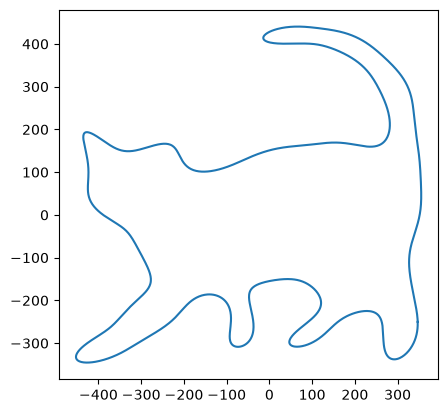

In [16]:
plt.gca().set_aspect("equal")
plt.plot(x, y)
plt.show()

Interesting... 

Have a closer look at the variables `x` and `y`. Note that they're linear combinations of sines and cosines. There's nothing more except sines and cosines, multiplied by coefficients. How are these able to generate the picture? Can we generate any picture?

Yes, we can generate pretty much anything and plot it as a parametric curve. See [this](https://www.wolframalpha.com/input/?i=Schroedinger+cat+bra-ket+curve) for example.

It turns out that **every function**, no matter what, can be represented as a linear combination of sines and cosines. This is the basis of the **Fourier transform**. We'll look at it from two different perspectives: the algebraic one and the practical one.

#### Algebraic perspective: Why does this transform exist? What does it mean?
All functions form a **vector space**. We can see them as vectors. These vectors have infinitely many components which correspond to the infinitely many values $x \in (-\infty; \infty)$. The function space has infinitely many dimensions.

We can find a basis in that space. After we've found a basis, we can express any other function as a linear combination of the basis functions. Any set of infinitely many linearly independent functions will work. But that doesn't help at all...

We know that the best kind of basis is an *orthonormal basis*. This means that all basis vectors are orthogonal and each basis vector has "length" 1. 

Two vectors are orthogonal if their dot product is zero. Similarly, two functions are defined to be orthogonal if their  product is zero, like this:
$$ \int_a^b f(x)g(x)\,\text{d}x = 0 $$

It can be shown that $1$, $\cos(mx)$ and $\sin(nx)$ ($m,n \in \mathbb{N}$) are orthogonal. So, the basis formed by them is orthogonal. They can also be made orthonormal if we divide by their norm. The norm of a function is defined by **functional analysis** - an area of mathematics which treats functions as vectors. We won't go into much more detail now. The norm for $1$ is 1, the norm for the trigonometric functions is $1/\sqrt{2}$.

The takeaway is that ${1, \sqrt{2}\cos(mx), \sqrt{2}\sin(nx),\ m,n \in \mathbb{N}}$ is an orthonormal basis in the function space. 

All periodic functions with period $P$ can be described as linear combinations of these:
$$ f(x) = \frac{a_0}{2} + \sum\left(a_n\cos\left(\frac{2\pi nx}{P}\right)+b_n\sin\left(\frac{2\pi nx}{P}\right)\right) $$

This definition extends to non-periodic functions as well.

### Parametric Curve — Experimental Results and Conclusion

**Experimental setup**

I generated 2000 values of the parameter $t$ in the interval:

$$
t \in [0, 2\pi]
$$

The coordinates were calculated using two Fourier series:

$$
x(t) = \sum_{n=1}^{30}
\left(a_n \cos(nt) + b_n \sin(nt)\right)
$$

$$
y(t) = \sum_{n=1}^{30}
\left(c_n \cos(nt) + d_n \sin(nt)\right)
$$

**Observations**

The resulting parametric curve forms a complex closed shape.

The individual sine and cosine functions are simple periodic waves, but their weighted combinations can represent complicated geometric outlines.

**Conclusion**

This experiment demonstrates how Fourier series can be used to construct complex parametric curves from simple trigonometric functions.

The same mathematical approach can be extended to geometric modeling, trajectory generation, and signal processing.

#### Engineering perspective
In engineering, the Fourier transform **converts a function of time to a function of frequency**. The function of time is called a **signal**, and the function of frequency is the **spectrum** of that signal. There is a pair of functions - one inverts the other. We have two different options:
1. We can inspect the spectrum
2. We can modify the spectrum

This means that if some operation is very easy to perform in the spectrum we can perform it there using these steps:
1. Create the spectrum from the signal - Fourier transform
2. Perform the operation, e.g. remove a specific frequency
3. Create the corrected signal from the corrected spectrum - inverse Fourier transform

One example usage is in audio processing. An audio signal is a  1D array of **samples** (numbers). Each audio signal has a *bitrate* which tells us how many samples are there in one second. Since audio is a function of time, we can easily get its spectrum.

Some algorithms on images use the spectrum as well. The idea is exactly the same.

Compare this entire process to how we created a **histogram**. Plotting a random variable $X$ as a function of the trial number is essentially plotting a function of time. To get the histogram, we counted how many times we saw each particular value. This is the same as taking the spectrum of the random variable.

### Problem 5. Working with Audio Files. Using the Fourier Transform
In Python, it's easiest to work with `.wav` files. If we have other files, we can convert them first. To load audio files, we can use `scipy.io.wavfile`. Load the `c-note.wav` file. Use only one channel, e.g. the left one.

C:\Users\SoftEng_PythonDjango\AppData\Local\Temp\ipykernel_15184\2105675214.py:1: WavFileWarning: Chunk (non-data) not understood, skipping it.
  bitrate, audio = scipy.io.wavfile.read("c-note.wav")


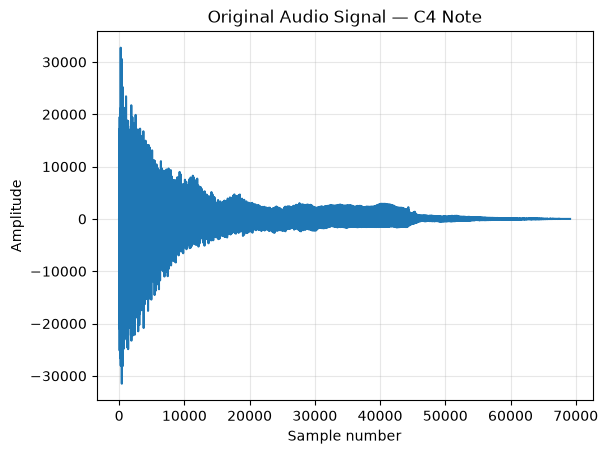

In [17]:
bitrate, audio = scipy.io.wavfile.read("c-note.wav")

left_channel = audio[:, 0]
right_channel = audio[:, 1]

plt.plot(left_channel)
plt.xlabel("Sample number")
plt.ylabel("Amplitude")
plt.title("Original Audio Signal — C4 Note")
plt.grid(alpha=0.3)
plt.show()

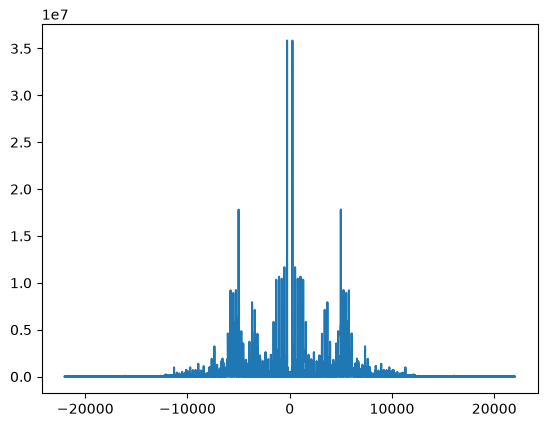

In [18]:
left_fft = fft(left_channel)

# fftfreq() returns the frequences in number of cycles per sample. Since we have `bitrate` samples in one second,
# to get the frequencies in Hz, we have to multiply by the bitrate
frequencies = fftfreq(len(left_channel)) * bitrate

plt.plot(frequencies, np.abs(left_fft))
plt.show()

Note that the signal is symmetric. This is always the case with Fourier transform. We are interested in only half the values (the ones which are $\ge 0$).

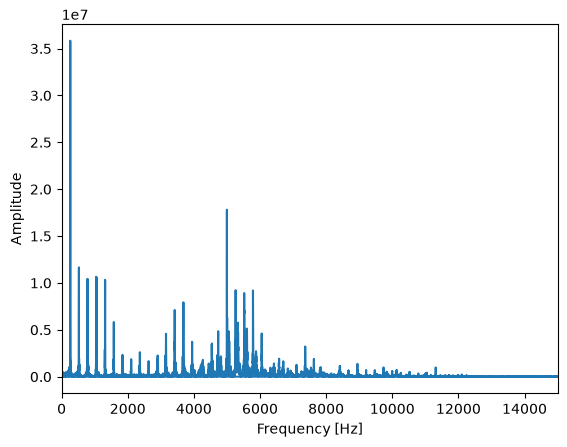

In [19]:
plt.plot(frequencies, np.abs(left_fft))
plt.xlim((0, 15000))
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.show()

We can see that some frequencies have higher intensities than others. Also, they are evenly spaced. This is because the sample is only one note: C4, which has a fundamental frequency of $261,6Hz$. Most other "loud" frequencies are a multiple of the fundamental frequency: these are called **obertones**. There are other frequencies as well. The combination of frequencies which one instrument emphasizes and the ones that it dampens (i.e. makes quiet) determines the specific sound, or **timbre** of that instrument.

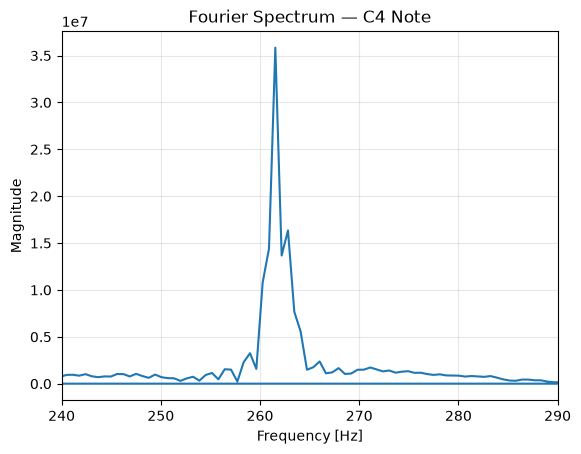

In [20]:
plt.plot(frequencies, np.abs(left_fft))

plt.xlim(240, 290)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Magnitude")
plt.title("Fourier Spectrum — C4 Note")
plt.grid(alpha=0.3)

plt.show()

### Experimental Results and Conclusion

The Fourier transform converts an audio signal from the time domain into the frequency domain.

The frequency spectrum shows a dominant peak near 261.6 Hz, corresponding to the musical note C4.

The magnitude of the Fourier coefficients is calculated using:

$$
|X(f)| = \sqrt{\operatorname{Re}(X(f))^2 + \operatorname{Im}(X(f))^2}
$$

The experiment demonstrates that:

- The original waveform represents changes in amplitude over time.
- The Fourier transform reveals the frequency components of the signal.
- The dominant frequency identifies the fundamental musical note.
- Additional frequency components contribute to the timbre of the instrument.

**Conclusion:** Fourier analysis provides a mathematical method for identifying frequencies in audio signals and is widely used in digital signal processing.

An interesting application of this is removal of unwanted frequencies. Look at [this video](https://www.youtube.com/watch?v=ATVbnilxIrs) for example. The highly annoying vuvuzela of 2010 World Cup turns out to produce only a single frequency which can be very easily removed from a recording.

Another interesting application of Fourier transform is filters (in audio and images).

### * Problem 6. Breaking MD5 in Different Ways
One relatively fast algorithm: $2^{18}$ instead of $2^{19}$ hashes for a 50% probability is described in [this](https://eprint.iacr.org/2013/170.pdf) article. It's the fastest known to date to break the MD5 function by brute force. Get familiar with it and implement the algorithm. Try to show how it works on some common (and short) plaintexts.

Experiment with other types of breaking the hash, for example using rainbow tables.

You can use the following checklist:
* What is a hash function? When are hash functions used?
* What is a cryptographic hash function?
* Why and how is a collision possible?
* What is a collision attack?
* What are the most common ways to attack hash functions?
    * Which cryptographic hash functions are no longer considered secure? Why?
* Why do websites have to store hashes of passwords instead of plaintext?
    * How does user login work?
* What is the "birthday attack"?
    * Provide an example of two plaintexts which produce the same hash
* What is the algorithm in the article about?
    * Implement it and show the result
* What is a rainbow table?
    * Try breaking common passwords using a rainbow table. You can generate one or use some table from the internet (e.g. English words and letters, their modifications, leaked passwords, etc.)
    * Even better, try a rainbow table first. If it doesn't work, try brute force
* How can a website protect its database against rainbow tables?
    * What is a "salt"? Additionally, what is "pepper"?
    * Is it always secure to hash a password multiple times? What advantages and disadvantages does this provide?

### 1. Hash Functions and Cryptographic Security

A hash function transforms input data of arbitrary length into
a fixed-length output called a hash value or digest.

A cryptographic hash function should have three important properties:

1. **Preimage resistance:** Given a hash, it should be computationally
   difficult to find an input that produces it.
2. **Second-preimage resistance:** Given an input, it should be
   difficult to find a different input with the same hash.
3. **Collision resistance:** It should be difficult to find any two
   different inputs that produce the same hash.

### 2. Why Are Collisions Possible?

A hash function maps an unlimited number of possible inputs
to a finite number of hash values.

According to the pigeonhole principle, collisions must exist.

For a hash function producing n-bit outputs, there are:

$$
N = 2^n
$$

possible hash values.

The birthday paradox explains why collisions can typically
be found after approximately:

$$
k \approx \sqrt{N} = 2^{n/2}
$$

random attempts.

For MD5, which produces 128-bit hashes, the birthday bound is
approximately:

$$
2^{64}
$$

attempts.

However, MD5 has structural weaknesses that allow specialized
collision attacks to perform much better than the generic
birthday bound.

### 3. MD5 and Password Security

MD5 is no longer considered collision-resistant and should not
be used for modern cryptographic security.

Websites should never store plaintext passwords.

Modern password storage uses dedicated password-hashing
algorithms such as Argon2id, scrypt, or bcrypt.

A unique random salt protects against precomputed hash tables.
A pepper is an additional secret stored separately from
the password database.

### 4. Collision Attacks and Password Recovery

A collision attack searches for two different inputs with
the same hash.

A password-recovery attack instead attempts to find an input
matching a specific stored password hash.

These are different security problems.

Rainbow tables use precomputed information to accelerate
password recovery against unsalted hashes.

Proper password hashing with unique salts makes such
precomputed tables impractical.

In [21]:
import hashlib

def short_md5(message):
    full_hash = hashlib.md5(
        message.encode("utf-8")
    ).hexdigest()

    return full_hash[:4]


seen_hashes = {}

for i in range(10000):
    message = f"message_{i}"
    hash_value = short_md5(message)

    if hash_value in seen_hashes:
        print("Collision found!")
        print("First message:", seen_hashes[hash_value])
        print("Second message:", message)
        print("Shared short hash:", hash_value)
        print("Messages tested:", i + 1)
        break

    seen_hashes[hash_value] = message
else:
    print("No collision found within 10000 messages.")

Collision found!
First message: message_253
Second message: message_703
Shared short hash: 1c53
Messages tested: 704


### Experimental Results and Conclusion

The experiment demonstrates the birthday paradox using
truncated MD5 hashes.

Two different messages produced the same 16-bit hash:

- First message: `message_253`
- Second message: `message_703`
- Shared hash: `1c53`
- Number of messages tested: 704

A 16-bit hash has:

$$
N = 2^{16} = 65536
$$

possible values.

The approximate number of random samples required for
a 50% probability of at least one collision is:

$$
k \approx \sqrt{2N\ln 2} \approx 301
$$

The experiment found a collision after 704 messages.

This result is consistent with the birthday paradox because
the number of attempts is a random variable, not a fixed value.

**Conclusion:**

The experiment illustrates how collisions can occur
much earlier than the total number of possible hash values.

However, the collision was found using truncated MD5 hashes.
It does not demonstrate a collision in the complete
128-bit MD5 algorithm.

In [22]:
import hashlib

# Small collection of example passwords
passwords = [
    "123456",
    "password",
    "admin",
    "qwerty",
    "hello123",
    "python123"
]

def md5_hash(text):
    return hashlib.md5(
        text.encode("utf-8")
    ).hexdigest()


# Build a simple precomputed hash lookup table
hash_table = {}

for password in passwords:
    hash_table[md5_hash(password)] = password


# Simulate a stored, unsalted password hash
target_hash = md5_hash("python123")

print("Target MD5 hash:", target_hash)

# Look up the password
recovered_password = hash_table.get(target_hash)

if recovered_password:
    print("Password found:", recovered_password)
else:
    print("Password not found in the table.")

Target MD5 hash: affaf271b3ebb2db157a04874259cdcb
Password found: python123


In [23]:
import hashlib
import secrets

password = "python123"

# Generate two independent random salts
salt_1 = secrets.token_hex(16)
salt_2 = secrets.token_hex(16)

def salted_md5(password, salt):
    data = (salt + password).encode("utf-8")
    return hashlib.md5(data).hexdigest()


hash_1 = salted_md5(password, salt_1)
hash_2 = salted_md5(password, salt_2)

print("Same password:", password)
print("Salt 1:", salt_1)
print("Salt 2:", salt_2)
print("Hash 1:", hash_1)
print("Hash 2:", hash_2)

print("Different hashes:", hash_1 != hash_2)

# Try the previously created unsalted lookup table
print("Found in old table:", hash_table.get(hash_1))

Same password: python123
Salt 1: 924ec84eb04f5aa1ecc658f7e68c607d
Salt 2: a9376bb707d8110558d1768e36b8ba85
Hash 1: a2e841e4f7d8f494823b8deed10dd494
Hash 2: 5126a1c2eeac5e9ddc5a75bde56fdfc1
Different hashes: True
Found in old table: None


### Experimental Results: Salt and Password Hashing

**Hypothesis:** Adding different random salts to the same password
will produce different hash values.

**Experiment:**

We used the password `python123` and generated two independent
random salts using Python's `secrets` module.

The results showed:

- The original password remained unchanged.
- The two randomly generated salts were different.
- The resulting MD5 hashes were different.
- The previously created unsalted lookup table could not
  recover the password from the salted hash.

**Mathematical representation:**

Without salt:

$$
h = H(p)
$$

With salt:

$$
h = H(s \Vert p)
$$

where:

- \(H\) is the hash function.
- \(p\) is the password.
- \(s\) is the random salt.
- \(\Vert\) represents concatenation.

**Conclusion:**

The experiment supports the hypothesis that different salts
produce different hashes for the same password.

A unique random salt prevents direct reuse of precomputed
unsalted hash lookup tables.

However, salting MD5 does not make it suitable for secure
password storage. Modern systems should use dedicated
password-hashing algorithms such as Argon2id, scrypt, or bcrypt.

A salt is not a secret. A pepper, in contrast, is a secret
value stored separately from the password database.

In [24]:
import hashlib
import hmac
import secrets

password = "python123"

salt = secrets.token_bytes(16)
pepper = secrets.token_bytes(32)

# Educational demonstration: salt + secret pepper
password_hash = hashlib.pbkdf2_hmac(
    "sha256",
    password.encode(),
    salt,
    200_000
)

protected_hash = hmac.new(
    pepper,
    password_hash,
    hashlib.sha256
).hexdigest()

print("Salt:", salt.hex())
print("Protected hash:", protected_hash)
print("Hash length:", len(protected_hash))

Salt: 60f1157d2d5f6947954714e0bb54ba75
Protected hash: 29a873a65cf09affb224455a8e9016b934c92b515f6fc56972bdf2372513ab70
Hash length: 64


### Experiment: Salt and Pepper

The experiment demonstrates two additional mechanisms for
protecting stored passwords.

**Salt** is a random value used during password hashing.
Different salts produce different hashes even when the
original passwords are identical. This makes precomputed
rainbow tables ineffective against properly salted hashes.

**Pepper** is a secret key stored separately from the
password database. It provides an additional layer of
protection if the database is compromised.

In this experiment, PBKDF2-HMAC-SHA256 was used for
password derivation, followed by HMAC-SHA256 with a
secret pepper.

**Conclusion:** Password security requires more than
a cryptographic hash function. Unique salts, secure
password-hashing algorithms, and careful management
of secret keys are essential.

### Multiple Hashing: Advantages and Limitations

Hashing a password multiple times can increase the
computational cost of password guessing attacks.

However, repeatedly applying a fast hash function
such as MD5 or SHA-256 is not a substitute for a
dedicated password-hashing algorithm.

**Advantages:**
- Increases the computational cost of each password guess.
- Can slow down brute-force and dictionary attacks.
- Allows configurable work factors in algorithms such as PBKDF2.

**Disadvantages:**
- Increases the computational cost of legitimate authentication.
- Excessive work factors can affect server performance.
- Repeated hashing does not compensate for weak passwords,
  missing salts, or insecure algorithms.

**Conclusion:**

Secure password storage requires an appropriate
password-hashing algorithm, unique random salts,
and carefully selected security parameters.

Argon2id is generally preferred for new applications.
PBKDF2 and scrypt are also established alternatives
when configured appropriately.

###  Problem 7. Audio Filters and Equalizers
Examine the behaviour of different filters and their influence on the input signal. The main kinds of filters are
* High-pass / low-pass
* Band-pass / band-stop

You can use the following checklist:
* What is a signal? What is time domain? What is frequency domain?
* How does the Fourier transform work?
    * Provide one (or more) examples with code
    * Optionally, show plots of some common functions (sine, step, pulse, sinc, gaussian) and their Fourier spectrums
* What is a filter?
* How does each type of filter work?
    * Provide examples, possibly with real data
* How do we combine filters and why?
* What is an equalizer?
    * Optionally, create an equalizer program or plugin that allows the user to emphasize or dampen different frequencies

### 7.1 Signals, Time Domain and Frequency Domain

A **signal** is a function that represents how a physical quantity changes over time or space.

Examples include:
- Sound waves
- Electrical signals
- Sensor measurements
- Digital audio recordings

#### Time Domain

The **time domain** represents a signal as a function of time:

$$
x(t)
$$

For example, an audio signal describes how sound amplitude changes over time.

#### Frequency Domain

The **frequency domain** represents the frequency components of a signal.

The Fourier transform converts a time-domain signal into its frequency-domain representation:

$$
X(f) = \int_{-\infty}^{\infty} x(t)e^{-i2\pi ft}\,dt
$$

where:

- $x(t)$ is the original signal.
- $X(f)$ is the frequency-domain representation.
- $f$ is frequency measured in hertz (Hz).
- $i$ is the imaginary unit.

#### What Is a Filter?

A **filter** modifies a signal by allowing certain frequency components to pass while reducing others.

The main types of filters are:

1. **Low-pass filter:** Passes low frequencies and attenuates high frequencies.
2. **High-pass filter:** Passes high frequencies and attenuates low frequencies.
3. **Band-pass filter:** Passes frequencies within a selected range.
4. **Band-stop filter:** Attenuates frequencies within a selected range.

#### Mathematical Model of Filtering

In the frequency domain, filtering can be represented as:

$$
Y(f) = H(f)X(f)
$$

where:

- $X(f)$ is the original signal spectrum.
- $H(f)$ is the frequency response of the filter.
- $Y(f)$ is the filtered signal spectrum.

This model describes linear time-invariant filtering.

#### Scientific Hypothesis

**Hypothesis:** Different filters will modify the frequency spectrum
of the same audio signal in different ways.

**Experiment:** Apply different filters to the audio file `c-note.wav`
and compare the original and filtered signals.

**Expected result:** Each filter will attenuate different frequency
components according to its frequency response.

C:\Users\SoftEng_PythonDjango\AppData\Local\Temp\ipykernel_15184\384186782.py:7: WavFileWarning: Chunk (non-data) not understood, skipping it.
  sample_rate, audio = wavfile.read("c-note.wav")


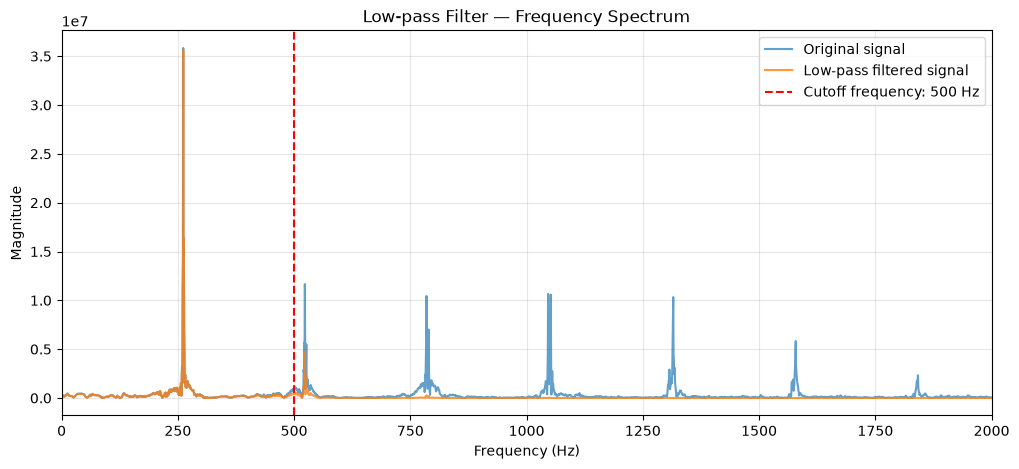

In [25]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import butter, sosfiltfilt

# Load the audio file
sample_rate, audio = wavfile.read("c-note.wav")

# Select the left channel if the recording is stereo
if audio.ndim == 2:
    signal = audio[:, 0]
else:
    signal = audio

# Convert to floating-point values
signal = signal.astype(np.float64)

# Design a 4th-order low-pass Butterworth filter
cutoff_frequency = 500  # Hz

sos = butter(
    4,
    cutoff_frequency,
    btype="lowpass",
    fs=sample_rate,
    output="sos"
)

# Apply the filter
filtered_signal = sosfiltfilt(sos, signal)

# Calculate frequency spectra
frequencies = np.fft.rfftfreq(
    len(signal),
    d=1 / sample_rate
)

original_spectrum = np.abs(np.fft.rfft(signal))
filtered_spectrum = np.abs(np.fft.rfft(filtered_signal))

# Plot the results
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    original_spectrum,
    label="Original signal",
    alpha=0.7
)

plt.plot(
    frequencies,
    filtered_spectrum,
    label="Low-pass filtered signal",
    alpha=0.8
)

plt.axvline(
    cutoff_frequency,
    color="red",
    linestyle="--",
    label="Cutoff frequency: 500 Hz"
)

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Low-pass Filter — Frequency Spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Low-pass Filter — Experimental Results and Conclusion

**Hypothesis:** A low-pass filter preserves low-frequency components while attenuating higher-frequency components.

**Experimental setup:**
- Input signal: `c-note.wav`
- Filter: 4th-order Butterworth low-pass filter
- Cutoff frequency: 500 Hz
- Method: Fourier spectrum comparison before and after filtering

**Observations:**
1. The fundamental frequency of the C4 note (approximately 261.6 Hz) remains almost unchanged.
2. The second harmonic (approximately 523 Hz) is attenuated.
3. Higher-frequency harmonics are strongly reduced.
4. The frequency response changes gradually rather than stopping abruptly at 500 Hz.

**Conclusion:**

The experiment supports the hypothesis. The low-pass filter preserves the fundamental frequency while reducing higher-frequency harmonics.

This demonstrates how digital filters can modify the frequency content of an audio signal without completely removing its fundamental tone.

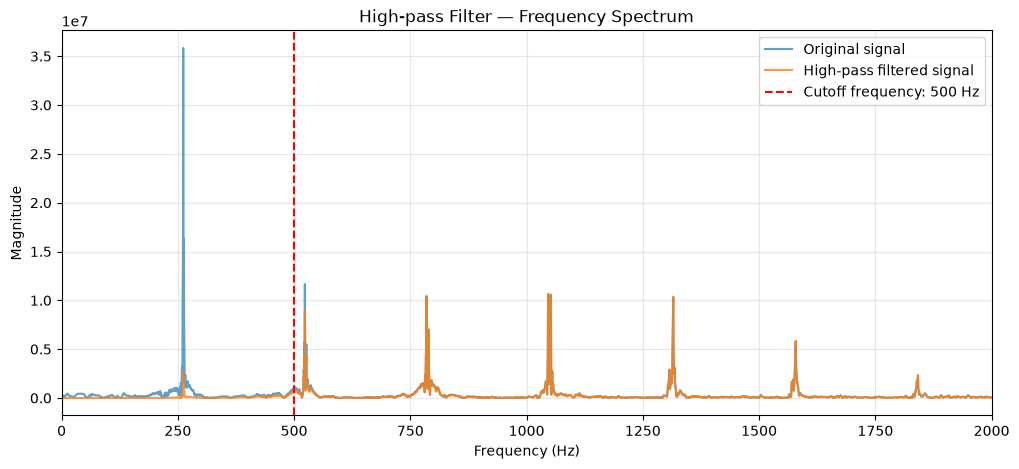

In [26]:
from scipy.signal import butter, sosfilt

# High-pass filter parameters
cutoff_frequency = 500
filter_order = 4

# Create the high-pass Butterworth filter
sos = butter(
    filter_order,
    cutoff_frequency,
    btype="highpass",
    fs=sample_rate,
    output="sos"
)

# Apply the filter to the audio signal
high_pass_audio = sosfilt(sos, left_channel)

# Calculate Fourier transforms
original_fft = np.fft.rfft(left_channel)
filtered_fft = np.fft.rfft(high_pass_audio)

frequencies = np.fft.rfftfreq(
    len(left_channel),
    d=1 / sample_rate
)

# Compare frequency spectra
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    np.abs(original_fft),
    label="Original signal",
    alpha=0.7
)

plt.plot(
    frequencies,
    np.abs(filtered_fft),
    label="High-pass filtered signal",
    alpha=0.8
)

plt.axvline(
    cutoff_frequency,
    color="red",
    linestyle="--",
    label="Cutoff frequency: 500 Hz"
)

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("High-pass Filter — Frequency Spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### High-pass Filter — Experimental Results and Conclusion

**Hypothesis:** A high-pass filter attenuates low-frequency components while preserving higher-frequency components.

**Experimental setup:**
- Input signal: `c-note.wav`
- Filter: 4th-order Butterworth high-pass filter
- Cutoff frequency: 500 Hz
- Method: Fourier spectrum comparison before and after filtering

**Observations:**

1. The fundamental frequency of the C4 note (approximately 261.6 Hz) is strongly attenuated.
2. The second harmonic (approximately 523 Hz) is partially attenuated.
3. Higher harmonics, including frequencies near 784 Hz, 1046 Hz, and 1308 Hz, remain relatively strong.
4. The transition between attenuated and preserved frequencies is gradual.

**Conclusion:**

The experiment supports the hypothesis.

The high-pass filter significantly reduces the fundamental frequency while preserving much of the higher-frequency content.

Unlike the low-pass filter, which emphasizes lower frequencies, the high-pass filter emphasizes higher-frequency components.

**Comparison:**

- Low-pass filter: preserves low frequencies and attenuates high frequencies.
- High-pass filter: preserves high frequencies and attenuates low frequencies.

Both filters can be used to modify the frequency spectrum and timbre of an audio signal.

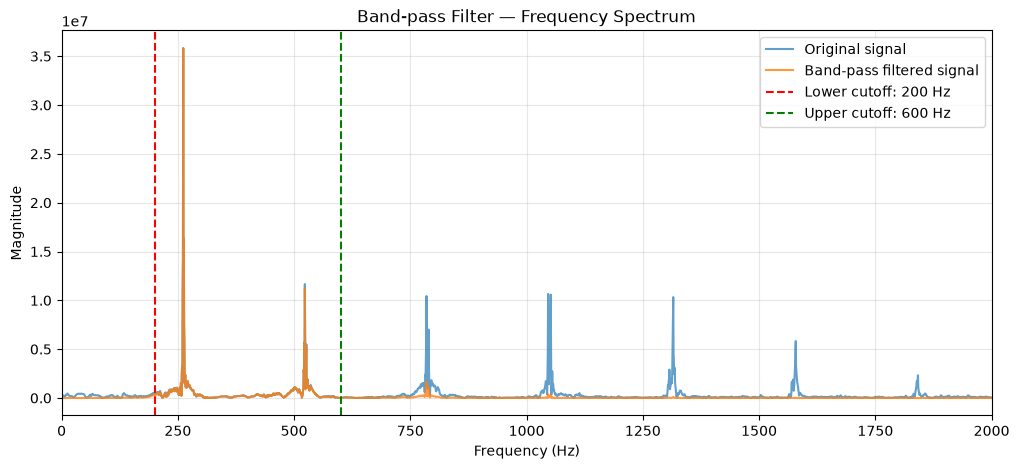

In [27]:
from scipy.signal import butter, sosfilt

# Band-pass filter parameters
low_cutoff = 200
high_cutoff = 600
filter_order = 4

# Create a Butterworth band-pass filter
sos = butter(
    filter_order,
    [low_cutoff, high_cutoff],
    btype="bandpass",
    fs=sample_rate,
    output="sos"
)

# Apply the filter
band_pass_audio = sosfilt(sos, left_channel)

# Calculate Fourier transforms
original_fft = np.fft.rfft(left_channel)
filtered_fft = np.fft.rfft(band_pass_audio)

frequencies = np.fft.rfftfreq(
    len(left_channel),
    d=1 / sample_rate
)

# Plot frequency spectra
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    np.abs(original_fft),
    label="Original signal",
    alpha=0.7
)

plt.plot(
    frequencies,
    np.abs(filtered_fft),
    label="Band-pass filtered signal",
    alpha=0.8
)

plt.axvline(
    low_cutoff,
    color="red",
    linestyle="--",
    label="Lower cutoff: 200 Hz"
)

plt.axvline(
    high_cutoff,
    color="green",
    linestyle="--",
    label="Upper cutoff: 600 Hz"
)

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Band-pass Filter — Frequency Spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Band-pass Filter — Experimental Results and Conclusion

**Hypothesis:** A band-pass filter preserves frequencies within a selected range while attenuating frequencies outside that range.

**Experimental setup:**
- Input signal: `c-note.wav`
- Filter: 4th-order Butterworth band-pass filter
- Lower cutoff frequency: 200 Hz
- Upper cutoff frequency: 600 Hz
- Method: Fourier spectrum comparison before and after filtering

**Observations:**

1. The fundamental frequency of the C4 note (approximately 261.6 Hz) remains strong.
2. The second harmonic (approximately 523 Hz) is partially attenuated.
3. Higher harmonics above 600 Hz are strongly reduced.
4. The filter has gradual transitions near its cutoff frequencies.

**Conclusion:**

The experiment supports the hypothesis.

The band-pass filter preserves the main frequency components within the selected 200–600 Hz range while attenuating frequencies outside it.

This type of filter is useful for isolating specific frequency bands in audio processing, communication systems, and signal analysis.

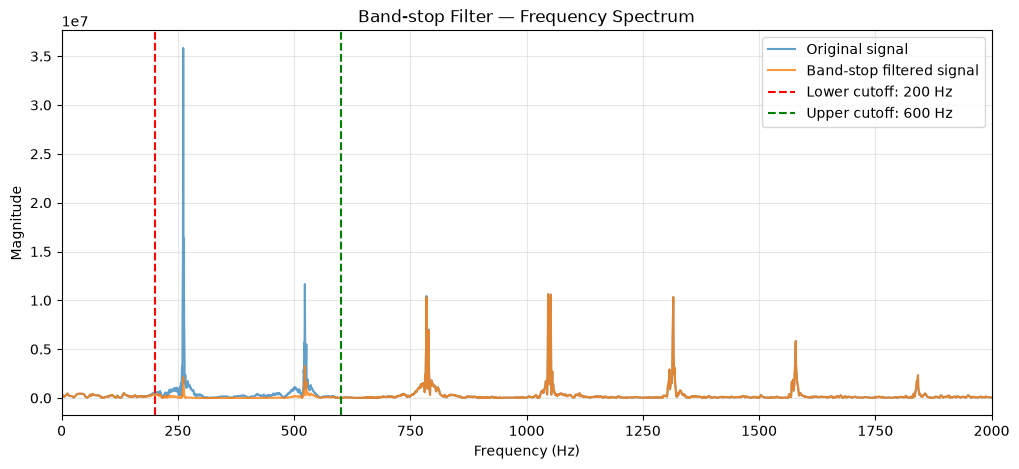

In [28]:
from scipy.signal import butter, sosfilt

# Band-stop filter parameters
low_cutoff = 200
high_cutoff = 600
filter_order = 4

# Create a Butterworth band-stop filter
sos = butter(
    filter_order,
    [low_cutoff, high_cutoff],
    btype="bandstop",
    fs=sample_rate,
    output="sos"
)

# Apply the filter
band_stop_audio = sosfilt(sos, left_channel)

# Calculate Fourier transforms
original_fft = np.fft.rfft(left_channel)
filtered_fft = np.fft.rfft(band_stop_audio)

frequencies = np.fft.rfftfreq(
    len(left_channel),
    d=1 / sample_rate
)

# Compare frequency spectra
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    np.abs(original_fft),
    label="Original signal",
    alpha=0.7
)

plt.plot(
    frequencies,
    np.abs(filtered_fft),
    label="Band-stop filtered signal",
    alpha=0.8
)

plt.axvline(
    low_cutoff,
    color="red",
    linestyle="--",
    label="Lower cutoff: 200 Hz"
)

plt.axvline(
    high_cutoff,
    color="green",
    linestyle="--",
    label="Upper cutoff: 600 Hz"
)

plt.xlim(0, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("Band-stop Filter — Frequency Spectrum")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Band-stop Filter — Experimental Results and Conclusion

**Hypothesis:** A band-stop filter attenuates frequencies within a selected range while preserving frequencies outside that range.

**Experimental setup:**
- Input signal: `c-note.wav`
- Filter: 4th-order Butterworth band-stop filter
- Lower cutoff frequency: 200 Hz
- Upper cutoff frequency: 600 Hz
- Method: Fourier spectrum comparison before and after filtering

**Observations:**

1. The fundamental frequency of the C4 note (approximately 261.6 Hz) is strongly attenuated.
2. The second harmonic (approximately 523 Hz) is also attenuated.
3. Higher harmonics, including frequencies near 784 Hz, 1046 Hz, and 1308 Hz, remain relatively strong.
4. The filter gradually changes its attenuation near the cutoff frequencies.

**Conclusion:**

The experiment supports the hypothesis.

The band-stop filter reduces frequency components within the selected 200–600 Hz range while preserving much of the frequency content outside that range.

Band-stop filters are useful for removing unwanted frequency bands, reducing interference, and improving signal quality.

### Comparison of the Four Filters

| Filter | Main Function |
|---|---|
| Low-pass | Preserves low frequencies and attenuates high frequencies |
| High-pass | Preserves high frequencies and attenuates low frequencies |
| Band-pass | Preserves frequencies within a selected range |
| Band-stop | Attenuates frequencies within a selected range |

**Final conclusion:**

Digital filters allow us to modify the frequency spectrum of an audio signal.

The experiments demonstrate how Fourier analysis helps us understand the effects of different filters on the original signal.

### Combining Filters and Audio Equalizers

#### 1. Why Do We Combine Filters?

Different filters can be combined to achieve more precise control over an audio signal.

For example:

- A high-pass filter can remove unwanted low-frequency noise.
- A low-pass filter can reduce high-frequency noise.
- Combining high-pass and low-pass filters can create a band-pass effect.
- A band-stop filter can suppress unwanted frequency bands.

When filters are connected in series, their frequency responses are multiplied.

$$
H_{\text{total}}(f) = H_1(f) \cdot H_2(f)
$$

Here:

- $H_1(f)$ is the frequency response of the first filter.
- $H_2(f)$ is the frequency response of the second filter.
- $H_{\text{total}}(f)$ is the combined frequency response.

#### 2. What Is an Audio Equalizer?

An audio equalizer is a system that adjusts the strength of different frequency bands.

Typical frequency regions include:

- **Bass:** approximately 20–250 Hz
- **Midrange:** approximately 250–4000 Hz
- **Treble:** approximately 4000–20000 Hz

An equalizer can increase or decrease the amplitude of selected frequency components.

For example, increasing bass emphasizes low-frequency sounds, while increasing treble emphasizes higher-frequency sounds.

#### 3. Connection with the Fourier Transform

The Fourier transform converts a time-domain signal into its frequency-domain representation.

$$
X(f) = \mathcal{F}\{x(t)\}
$$

A frequency-domain filter modifies the spectrum:

$$
Y(f) = H(f)X(f)
$$

The inverse Fourier transform converts the modified spectrum back into a time-domain signal:

$$
y(t) = \mathcal{F}^{-1}\{Y(f)\}
$$

This mathematical approach provides the foundation for many digital audio-processing techniques.

#### 4. Final Conclusion

The experiments demonstrate that digital filters can selectively attenuate or preserve different frequency components.

Combining filters provides greater flexibility, while equalizers allow more detailed control over the frequency balance of an audio signal.

Fourier analysis makes it possible to visualize, understand, and modify signals in the frequency domain.


###  Problem 8. Error-Correcting Codes
In communication and data storage, it's important to prevent, detect, and possibly correct errors (such as errors in data transmission). There are various schemes to implement such correction, mainly by sending additional info with the data. A popular such scheme is the [Hamming code](https://en.wikipedia.org/wiki/Hamming_code). Your task is to explore how it works, implement an example, and compare it to other error detection and correction mechanisms.
* What is an error-correcting code? Why are they important?
* What are the different types of error-correcting codes? Provide real-world examples.
* What is a **Hamming code**? Describe the history and / or derive the formula(s). 
* What are parity bits and how do we use them?
* What is the Hamming distance and what is its significance? How is it related to other distance metrics for text / bit sequences?
* Deeper dive into mathematics:
    * Derive the general formula for the number of parity bits required for a given number of data bits.
    * Explain the process of encoding data using Hamming codes. How are parity bits positioned in the data?
    * Describe the process of detecting and correcting errors using Hamming codes. How are syndrome vectors used in this process?
* Implement encoding / decoding, error detection and error correction
    * Simplest case - illustrate one-bit detection / correction
    * Apply the encoding scheme to a real-world scenario
    * Compare your implementation to a Python library. Discuss efficiency, timing, code quality, etc.
* Discussion:
    * What are the limitations of Hamming codes? How do more advanced error-correcting codes address these limitations?
    * Research at least one other error-correcting codes used in industry. Compare their complexity and effectiveness with Hamming codes. Provide at least one real-world example (and edge cases, if possible).

### 8.1 Introduction to Error-Correcting Codes

#### What Is an Error-Correcting Code?

An error-correcting code is a mathematical method used to detect and correct errors in transmitted or stored information.

During data transmission, individual bits may change because of electrical noise, interference, hardware failures, or other disturbances.

For example, an original binary message:

`1011`

might be received as:

`1001`

The third bit has changed from 1 to 0.

Error-correcting codes introduce additional redundant bits that help the receiver detect and, in some cases, correct such errors.

#### Why Are Error-Correcting Codes Important?

Error detection and correction are essential in:

- Digital communication systems
- Computer memory
- Satellite and space communication
- Data storage devices
- Wireless networks
- Optical and digital communication channels

#### Types of Error Detection and Correction

**1. Parity Check**

A parity bit is added to a binary message to make the total number of ones either even or odd.

A simple parity check can detect any odd number of bit errors, but it cannot identify or correct the erroneous bit.

**2. Hamming Codes**

Hamming codes use multiple parity bits to identify the position of an erroneous bit.

A standard Hamming code can correct one-bit errors.

**3. Reed–Solomon Codes**

Reed–Solomon codes are designed to correct multiple symbol errors.

They are used in data storage, QR codes, and communication systems.

**4. BCH Codes**

BCH codes are a family of error-correcting codes that can be designed to correct multiple bit errors.

They are used in communication and storage technologies.

**5. LDPC Codes**

Low-Density Parity-Check codes use sparse parity-check matrices and iterative decoding algorithms.

They are used in modern communication systems.

### 8.2 Hamming Codes

Hamming codes were introduced by Richard Hamming in 1950.

Their purpose is to provide an efficient method for detecting and correcting errors in binary data.

A standard Hamming code adds parity bits to the original data.

These parity bits are placed at positions that are powers of two:

$$
1,\ 2,\ 4,\ 8,\ 16,\ldots
$$

All other positions contain data bits.

#### Number of Required Parity Bits

Let:

- $m$ = number of data bits
- $r$ = number of parity bits
- $n = m + r$ = total number of encoded bits

For a single-error-correcting Hamming code, the number of parity bits must satisfy:

$$
2^r \geq m + r + 1
$$

The reason is that the parity bits must distinguish between:

- No error
- An error at any of the $m+r$ bit positions

Therefore, at least $m+r+1$ distinct states are required.

#### Example: Four Data Bits

For $m = 4$:

If $r = 2$:

$$
2^2 = 4 < 4 + 2 + 1 = 7
$$

Two parity bits are insufficient.

If $r = 3$:

$$
2^3 = 8 \geq 4 + 3 + 1 = 8
$$

Three parity bits are sufficient.

Thus, four data bits require three parity bits.

The resulting code is called **Hamming(7,4)**.

It contains:

- 4 data bits
- 3 parity bits
- 7 total encoded bits

### 8.3 Hamming Distance

The Hamming distance between two binary strings of equal length is the number of positions at which their bits differ.

For example:

`101101`

`100111`

The strings differ at two positions.

Therefore:

$$
d_H(101101,\ 100111) = 2
$$

For a code with minimum Hamming distance $d_{\min}$:

- It can detect up to $d_{\min}-1$ bit errors.
- It can correct up to $\left\lfloor (d_{\min}-1)/2 \right\rfloor$ bit errors.

A standard Hamming(7,4) code has:

$$
d_{\min}=3
$$

Therefore, it can correct one-bit errors.

A standard Hamming(7,4) code has a minimum Hamming distance of:

$$
d_{\min} = 3
$$

Therefore, the code can:

- **Correct any single-bit error.**
- **Detect up to two-bit errors**, when error detection is performed without attempting automatic correction.

**Important limitation:**

A standard single-error-correcting Hamming decoder cannot reliably distinguish a two-bit error from a single-bit error.

When two bits are corrupted, the decoder may incorrectly flip a third bit, producing another valid but incorrect codeword.

An extended Hamming code (**SECDED — Single Error Correction, Double Error Detection**) adds an overall parity bit, allowing reliable single-bit error correction and double-bit error detection.

### 8.4 Hamming(7,4) — Encoding Example

We want to encode four data bits:

`1011`

Hamming(7,4) uses three parity bits, placed at positions 1, 2, and 4.

| Position | 1 | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|---|
| Type | P1 | P2 | D1 | P4 | D2 | D3 | D4 |
| Value | ? | ? | 1 | ? | 0 | 1 | 1 |

We use even parity.

The XOR operation produces 1 when the two input bits differ and 0 when they are equal.

**Parity bit P1** checks positions 1, 3, 5, and 7:

$$
P_1 = D_1 \oplus D_2 \oplus D_4
$$

$$
P_1 = 1 \oplus 0 \oplus 1 = 0
$$

**Parity bit P2** checks positions 2, 3, 6, and 7:

$$
P_2 = D_1 \oplus D_3 \oplus D_4
$$

$$
P_2 = 1 \oplus 1 \oplus 1 = 1
$$

**Parity bit P4** checks positions 4, 5, 6, and 7:

$$
P_4 = D_2 \oplus D_3 \oplus D_4
$$

$$
P_4 = 0 \oplus 1 \oplus 1 = 0
$$

The resulting encoded message is:

**`0110011`**

The original four data bits have been extended to seven bits.

These additional parity bits allow a Hamming(7,4) decoder to identify and correct any single-bit error.

In [29]:
def hamming_encode(data):
    """Encode four binary digits using Hamming(7,4)."""
    if len(data) != 4 or any(bit not in "01" for bit in data):
        raise ValueError("Input must contain exactly four binary digits.")

    d1, d2, d3, d4 = map(int, data)

    p1 = d1 ^ d2 ^ d4
    p2 = d1 ^ d3 ^ d4
    p4 = d2 ^ d3 ^ d4

    encoded = [p1, p2, d1, p4, d2, d3, d4]

    return "".join(map(str, encoded))


original_data = "1011"
encoded_data = hamming_encode(original_data)

print("Original data:", original_data)
print("Encoded data:", encoded_data)
print("Total bits:", len(encoded_data))


Original data: 1011
Encoded data: 0110011
Total bits: 7


In [30]:
# Simulate a single-bit transmission error

received = list(encoded_data)

error_position = 5  # Positions start from 1

# Flip the bit at position 5
index = error_position - 1
received[index] = "1" if received[index] == "0" else "0"

received_data = "".join(received)

print("Original encoded data:", encoded_data)
print("Received data:", received_data)
print("Error position:", error_position)


Original encoded data: 0110011
Received data: 0110111
Error position: 5


In [31]:
# Detect a single-bit error using the Hamming syndrome

bits = [int(bit) for bit in received_data]

s1 = bits[0] ^ bits[2] ^ bits[4] ^ bits[6]
s2 = bits[1] ^ bits[2] ^ bits[5] ^ bits[6]
s4 = bits[3] ^ bits[4] ^ bits[5] ^ bits[6]

# The syndrome identifies the error position
detected_position = s1 + 2 * s2 + 4 * s4

print("Syndrome bits:", s4, s2, s1)
print("Detected error position:", detected_position)

Syndrome bits: 1 0 1
Detected error position: 5


In [32]:
# Correct the detected single-bit error

corrected_bits = bits.copy()

if detected_position != 0:
    index = detected_position - 1

    # Flip the incorrect bit
    corrected_bits[index] ^= 1

corrected_data = "".join(map(str, corrected_bits))

# Extract the original data bits from positions 3, 5, 6, 7
decoded_data = "".join(
    str(corrected_bits[i]) for i in [2, 4, 5, 6]
)

print("Received data:", received_data)
print("Detected error position:", detected_position)
print("Corrected data:", corrected_data)
print("Decoded original data:", decoded_data)
print("Correction successful:", corrected_data == encoded_data)


Received data: 0110111
Detected error position: 5
Corrected data: 0110011
Decoded original data: 1011
Correction successful: True


### Hamming(7,4) — Mathematical Explanation and Experimental Results

#### 1. Purpose

Hamming codes are error-correcting codes that add redundant bits to binary data. This redundancy allows the receiver to detect and correct a single-bit transmission error.

#### 2. Number of Parity Bits

For `m` data bits and `r` parity bits, the following condition must hold:

$$
2^r \geq m + r + 1
$$

For four data bits:

$$
m = 4,\qquad r = 3
$$

$$
2^3 = 8 \geq 4 + 3 + 1 = 8
$$

Therefore, Hamming(7,4) uses four data bits and three parity bits.

#### 3. Encoding

The parity bits occupy positions that are powers of two:

$$
1,\ 2,\ 4
$$

The data bits occupy positions:

$$
3,\ 5,\ 6,\ 7
$$

Our experiment produced:

- Original data: `1011`
- Encoded data: `0110011`

We use even parity.

#### 4. Error Detection Using the Syndrome

The parity-check groups are:

- $s_1$: positions 1, 3, 5, 7
- $s_2$: positions 2, 3, 6, 7
- $s_4$: positions 4, 5, 6, 7

Each syndrome bit is calculated using XOR.

The error position is:

$$
e = s_1 + 2s_2 + 4s_4
$$

In our experiment:

$$
(s_4s_2s_1)_2 = (101)_2 = 5
$$

Therefore, the error was detected at position 5.

#### 5. Experimental Results

| Stage | Binary sequence |
|---|---|
| Original data | `1011` |
| Encoded data | `0110011` |
| Received data with error | `0110111` |
| Detected error position | `5` |
| Corrected data | `0110011` |
| Decoded data | `1011` |

The experiment confirmed that the original four data bits were successfully recovered after a single-bit transmission error.

#### 6. Limitations

Standard Hamming(7,4) has a minimum Hamming distance of 3.

It can:

- Correct one erroneous bit.
- Detect up to two erroneous bits if detection is considered separately.
- Fail to correct correctly when multiple bits are corrupted.

An extended Hamming code with an additional overall parity bit can provide single-error correction and double-error detection (SECDED).

#### 7. Conclusion

The experiment demonstrates how mathematical redundancy improves the reliability of digital communication.

By calculating the syndrome, the receiver can identify and correct a single-bit error without knowing its position in advance.

Hamming codes are an important foundation for understanding error correction in computer memory, communication systems, and data storage.

In [33]:
# Calculate the Hamming distance between two binary sequences

def hamming_distance(a: str, b: str) -> int:
    if len(a) != len(b):
        raise ValueError("Binary sequences must have equal lengths.")

    return sum(bit_a != bit_b for bit_a, bit_b in zip(a, b))


distance_before = hamming_distance(encoded_data, received_data)
distance_after = hamming_distance(encoded_data, corrected_data)

print("Original encoded data:", encoded_data)
print("Received data:", received_data)
print("Hamming distance before correction:", distance_before)
print("Hamming distance after correction:", distance_after)

Original encoded data: 0110011
Received data: 0110111
Hamming distance before correction: 1
Hamming distance after correction: 0


### Comparison of Error Detection and Correction Methods

Different error-control techniques provide different levels of protection against corrupted data.

| Method | Error Detection | Error Correction | Typical Applications |
|---|---|---|---|
| Parity Bit | Detects an odd number of bit errors | No | Simple communication systems |
| CRC (Cyclic Redundancy Check) | Detects many common error patterns | No | Ethernet, data transmission, storage |
| Hamming(7,4) | Detects up to two bit errors | Corrects one bit error | Digital communication, educational examples |
| Extended Hamming (SECDED) | Detects two bit errors | Corrects one bit error | ECC computer memory |
| Reed–Solomon | Detects multiple symbol errors | Corrects multiple symbol errors | QR codes, optical storage, communication systems |

#### Hamming Code vs. Reed–Solomon Code

Hamming codes use parity bits to protect binary data. The standard Hamming(7,4) code adds three parity bits to four data bits.

Reed–Solomon codes operate on symbols rather than individual bits. They are especially useful for correcting burst errors, where several consecutive bits or symbols become corrupted.

For a Reed–Solomon code with `n` total symbols and `k` data symbols, the number of redundant symbols is:

$$
r = n-k
$$

The maximum number of unknown symbol errors that can be corrected is:

$$
t = \left\lfloor \frac{n-k}{2} \right\rfloor
$$

For example, a Reed–Solomon RS(255,223) code has 32 redundant symbols and can correct up to 16 unknown symbol errors.

#### Experimental Conclusion

Our Hamming(7,4) experiment produced the following results:

- Original data: `1011`
- Encoded data: `0110011`
- Corrupted data: `0110111`
- Detected error position: `5`
- Corrected data: `0110011`
- Decoded data: `1011`
- Hamming distance before correction: `1`
- Hamming distance after correction: `0`

The experiment confirms successful single-bit error correction.

Hamming codes are relatively simple and efficient for correcting isolated bit errors. More advanced codes, such as Reed–Solomon, provide stronger protection against multiple errors but require more complex calculations.

**Limitation:** Standard Hamming(7,4) cannot reliably correct two simultaneous bit errors. Extended Hamming codes add an overall parity bit to distinguish single-bit errors from double-bit errors.

In [34]:
# Experiment: Two simultaneous bit errors in Hamming(7,4)

original = encoded_data
corrupted = [int(bit) for bit in original]

# Introduce errors at positions 3 and 5
corrupted[2] ^= 1
corrupted[4] ^= 1

received_two_errors = "".join(map(str, corrupted))

# Calculate the Hamming syndrome
s1 = corrupted[0] ^ corrupted[2] ^ corrupted[4] ^ corrupted[6]
s2 = corrupted[1] ^ corrupted[2] ^ corrupted[5] ^ corrupted[6]
s4 = corrupted[3] ^ corrupted[4] ^ corrupted[5] ^ corrupted[6]

syndrome = s1 + 2 * s2 + 4 * s4

# Attempt single-bit correction
attempted = corrupted.copy()

if syndrome != 0:
    attempted[syndrome - 1] ^= 1

attempted_data = "".join(map(str, attempted))

print("Original encoded data:", original)
print("Received with two errors:", received_two_errors)
print("Syndrome:", syndrome)
print("Attempted correction:", attempted_data)
print("Correction successful:", attempted_data == original)
print("Remaining Hamming distance:",
      hamming_distance(original, attempted_data))


Original encoded data: 0110011
Received with two errors: 0100111
Syndrome: 6
Attempted correction: 0100101
Correction successful: False
Remaining Hamming distance: 3


### Experiment: Limitations of Hamming(7,4) with Two-Bit Errors

#### Hypothesis

The standard Hamming(7,4) code can correct a single-bit error but cannot reliably correct two simultaneous bit errors.

#### Experimental Setup

We started with the valid encoded message:

`0110011`

We deliberately changed the bits at positions 3 and 5.

The received message became:

`0100111`

We then calculated the Hamming syndrome and applied the standard single-bit correction procedure.

#### Experimental Results

| Measurement | Result |
|---|---|
| Original encoded message | `0110011` |
| Received message | `0100111` |
| Number of introduced errors | 2 |
| Calculated syndrome | 6 |
| Attempted correction | `0100101` |
| Correction successful | False |
| Remaining Hamming distance | 3 |

#### Mathematical Explanation

For two erroneous bit positions, the syndrome is the bitwise XOR of their position numbers.

In our experiment:

$$
3 \oplus 5 = 6
$$

Therefore, the decoder incorrectly identified position 6 as a single-bit error.

After changing this bit, the resulting codeword differed from the original in three positions.

The minimum Hamming distance of the Hamming(7,4) code is:

$$
d_{\min}=3
$$

The maximum guaranteed number of correctable errors is:

$$
t=\left\lfloor\frac{d_{\min}-1}{2}\right\rfloor=1
$$

#### Conclusion

The experimental results support our hypothesis.

Hamming(7,4) successfully corrected a single-bit error in the previous experiment but failed when two bits were corrupted simultaneously.

The nonzero syndrome indicated that the received message was invalid, but it did not reveal that two errors had occurred.

This demonstrates an important limitation: the standard single-error-correction decoder cannot reliably distinguish one-bit errors from two-bit errors.

Extended Hamming codes (SECDED) add an overall parity bit, allowing reliable single-error correction and double-error detection.

### Problem 9. Probabilistic Data Structures
A very interesting application of probability in computer science is a kind of data structures which have a probabilistic behaviour. Examples of these are **Bloom filter**, **Skip list**, **Count-min sketch** and **HyperLogLog**.

Research how one of these structures works. Or write about many of them, if you wish. You can use the following checklist as a guide:
* What is a data structure? 
* What is a probabilistic data structure?
    * Where does the probabilistic behaviour emerge?
    * What advantages do these structures provide?
* For your chosen structure, how is it constructed?
    * What parts do you need? What are the details?
* How does the structure work?
    * What operations can you do?
    * What are the typical probabilities associated with these operations?
* Analyze the structure
    * Analyze the runtimes for all operations
    * Analyze the space usage
    * Compare to a similar, non-probabilistic data structure
    * What advantages does the new data structure have? What drawbacks do you need to be aware of?
* Give at least one example where this structure is useful
    * E.g., Bloom filter - spell checkers
    * Analyze the use case
    * If possible, implement the use case
    * Display some metrics (e.g. % conserved space, % reduced time)

### Bloom Filter — A Probabilistic Data Structure

#### 1. What Is a Data Structure?

A data structure is a method of organizing and storing data so that operations such as insertion, searching, and deletion can be performed efficiently.

Examples include arrays, lists, hash tables, trees, and sets.

#### 2. What Is a Probabilistic Data Structure?

A probabilistic data structure uses mathematical techniques to reduce memory consumption or improve efficiency while allowing a controlled probability of error.

Examples include Bloom filters, Skip lists, Count-Min Sketch, and HyperLogLog.

#### 3. What Is a Bloom Filter?

A Bloom filter is a space-efficient probabilistic data structure used to test whether an element is possibly present in a set.

It consists of:

- A bit array containing `m` bits, initially set to zero.
- `k` hash functions.
- A Bloom filter does not store the original inserted elements. Instead, it records their hash positions in the bit array.

#### 4. How Does It Work?

**Insertion:**

1. Calculate `k` hash values for the element.
2. Convert these values into positions in the bit array.
3. Set the corresponding bits to 1.

**Membership test:**

1. Calculate the same `k` hash positions.
2. If at least one corresponding bit is 0, the element is definitely absent.
3. If all corresponding bits are 1, the element is possibly present.

A standard Bloom filter can produce false positives but not false negatives, assuming elements are only inserted and the filter is used correctly.

#### 5. Mathematical Model

Let:

- `m` = number of bits in the filter
- `n` = number of inserted elements
- `k` = number of hash functions

The approximate false-positive probability is:

$$
p \approx \left(1-e^{-kn/m}\right)^k
$$

The approximately optimal number of hash functions is:

$$
k_{\mathrm{opt}}=\frac{m}{n}\ln 2
$$

For a desired false-positive probability `p`, the approximate required number of bits is:

$$
m=-\frac{n\ln p}{(\ln 2)^2}
$$

**Optimal Number of Hash Functions — Important Clarification**

The optimal number of hash functions depends on the ratio between
the Bloom filter size (`m`) and the number of inserted elements (`n`):

$$
k_{\mathrm{opt}} = \frac{m}{n}\ln 2
$$

Since the number of hash functions must be a positive integer,
the calculated value is rounded to a suitable integer.

In our experiments, we keep `k = 3` constant while changing
the filter size `m`.

Therefore, the experiments demonstrate how increasing the
filter size affects the false-positive probability when the
number of hash functions remains fixed.

They do not demonstrate the optimal configuration for each
filter size.

#### 6. Time and Space Complexity

| Operation | Complexity |
|---|---|
| Insert an element | O(k) |
| Check membership | O(k) |
| Initialize bit array | O(m) |
| Space usage | O(m) bits |

A standard Bloom filter does not support safe deletion because multiple elements may share the same bit positions.

#### 7. Practical Applications

Bloom filters are useful in:

- Database systems to avoid unnecessary disk lookups.
- Web crawlers to identify potentially visited URLs.
- Spell-checking systems to test whether words may exist in a dictionary.
- Distributed systems to reduce unnecessary data access.

#### 8. Comparison with a Python Set

A Python set stores actual elements and provides exact membership testing.

A Bloom filter stores only a compact bit representation and allows a small probability of false positives.

The main advantage is lower memory usage for large collections.

The main disadvantages are false positives, inability to retrieve the original elements, and lack of safe deletion in the standard implementation.

#### 9. Experimental Hypothesis

Increasing the size of the bit array while keeping the number of inserted elements constant should reduce the false-positive probability.

We will implement a Bloom filter in Python and compare the measured false-positive rate with the theoretical prediction.

In [35]:
import hashlib


class BloomFilter:
    def __init__(self, size=1000, hash_count=3):
        self.size = size
        self.hash_count = hash_count
        self.bit_array = bytearray((size + 7) // 8)

    def _hashes(self, item):
        item = str(item).encode("utf-8")

        for i in range(self.hash_count):
            data = i.to_bytes(4, "big") + item
            digest = hashlib.sha256(data).digest()
            hash_value = int.from_bytes(digest, "big")
            yield hash_value % self.size

    def add(self, item):
        for position in self._hashes(item):
            byte_index = position // 8
            bit_index = position % 8
            self.bit_array[byte_index] |= 1 << bit_index

    def contains(self, item):
        for position in self._hashes(item):
            byte_index = position // 8
            bit_index = position % 8

            if not (self.bit_array[byte_index] & (1 << bit_index)):
                return False

        return True


# Create a Bloom filter
bloom = BloomFilter(size=1000, hash_count=3)

# Insert elements
bloom.add("python")
bloom.add("mathematics")
bloom.add("geometry")

# Test membership
print("python:", bloom.contains("python"))
print("mathematics:", bloom.contains("mathematics"))
print("geometry:", bloom.contains("geometry"))
print("javascript:", bloom.contains("javascript"))
print("Memory used for bit array:", len(bloom.bit_array), "bytes")

python: True
mathematics: True
geometry: True
javascript: False
Memory used for bit array: 125 bytes


In [36]:
import numpy as np

# Experiment parameters
m = 1000
n = 100
k = 3
num_tests = 1000

# Create a new Bloom filter
experiment_filter = BloomFilter(
    size=m,
    hash_count=k
)

# Insert 100 elements
for i in range(n):
    experiment_filter.add(f"word_{i}")

# Test 1000 elements that were not inserted
false_positives = 0

for i in range(num_tests):
    word = f"test_word_{i}"

    if experiment_filter.contains(word):
        false_positives += 1

# Experimental false-positive probability
experimental_p = false_positives / num_tests

# Theoretical false-positive probability
theoretical_p = (1 - np.exp(-k * n / m)) ** k

print("Inserted elements:", n)
print("Tested elements:", num_tests)
print("False positives:", false_positives)
print(f"Experimental probability: {experimental_p:.4f}")
print(f"Theoretical probability: {theoretical_p:.4f}")
print(f"Experimental percentage: {experimental_p * 100:.2f}%")
print(f"Theoretical percentage: {theoretical_p * 100:.2f}%")

Inserted elements: 100
Tested elements: 1000
False positives: 21
Experimental probability: 0.0210
Theoretical probability: 0.0174
Experimental percentage: 2.10%
Theoretical percentage: 1.74%


Size:  500 bits | Experimental: 11.30% | Theoretical: 9.18%
Size: 1000 bits | Experimental: 2.10% | Theoretical: 1.74%
Size: 2000 bits | Experimental: 0.30% | Theoretical: 0.27%
Size: 4000 bits | Experimental: 0.20% | Theoretical: 0.04%
Size: 8000 bits | Experimental: 0.00% | Theoretical: 0.00%


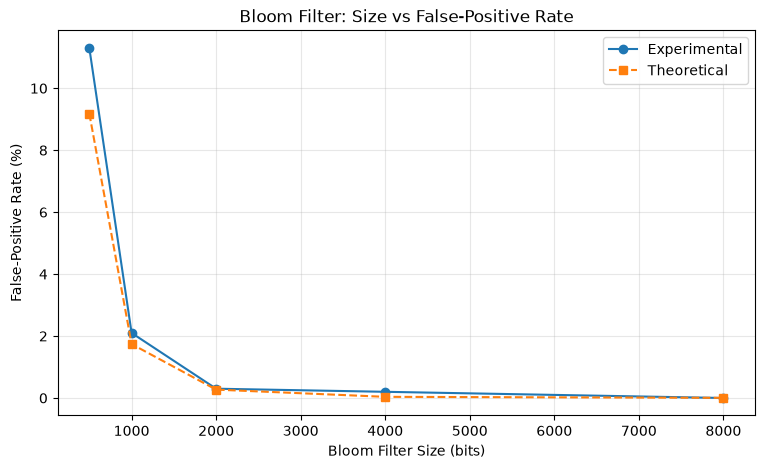

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Experiment: Effect of Bloom filter size

sizes = [500, 1000, 2000, 4000, 8000]

n = 100
k = 3
num_tests = 1000

experimental_rates = []
theoretical_rates = []

for m in sizes:
    bloom = BloomFilter(size=m, hash_count=k)

    # Insert 100 elements
    for i in range(n):
        bloom.add(f"word_{i}")

    # Count false positives
    false_positives = 0

    for i in range(num_tests):
        if bloom.contains(f"test_word_{i}"):
            false_positives += 1

    experimental_p = false_positives / num_tests
    theoretical_p = (1 - np.exp(-k * n / m)) ** k

    experimental_rates.append(experimental_p * 100)
    theoretical_rates.append(theoretical_p * 100)

    print(
        f"Size: {m:4d} bits | "
        f"Experimental: {experimental_p * 100:.2f}% | "
        f"Theoretical: {theoretical_p * 100:.2f}%"
    )

# Plot results
plt.figure(figsize=(9, 5))

plt.plot(
    sizes,
    experimental_rates,
    marker="o",
    label="Experimental"
)

plt.plot(
    sizes,
    theoretical_rates,
    marker="s",
    linestyle="--",
    label="Theoretical"
)

plt.title("Bloom Filter: Size vs False-Positive Rate")
plt.xlabel("Bloom Filter Size (bits)")
plt.ylabel("False-Positive Rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Experimental Results and Conclusion

**Hypothesis:** Increasing the Bloom filter size reduces the false-positive probability when the number of inserted elements and hash functions remains constant.

We tested five Bloom filter sizes: 500, 1000, 2000, 4000, and 8000 bits.

For each experiment:
- 100 elements were inserted.
- 1000 elements that were not inserted were tested.
- Three hash functions were used.
- Experimental and theoretical false-positive rates were compared.

**Observations:**

The experimental false-positive rate decreased from 11.30% with 500 bits to 0.00% with 8000 bits.

The experimental results generally followed the theoretical predictions.

Small differences between theoretical and experimental values are expected because the experiment uses a finite number of tests.

**Conclusion:**

The experiment supports our hypothesis.

A larger Bloom filter requires more memory but reduces the probability of false positives.

Bloom filters provide a trade-off between memory efficiency and accuracy.

A false-positive rate of 0% in a finite experiment does not guarantee that false positives are impossible.

Bloom filters are useful when memory efficiency is important and occasional false positives are acceptable.

In [38]:
import sys

# Create 100 elements
elements = [f"word_{i}" for i in range(100)]

# Standard Python set
python_set = set(elements)

# Bloom filter configuration
bloom_size_bits = 1000
bloom_size_bytes = (bloom_size_bits + 7) // 8

# Calculate memory usage
set_memory = (
    sys.getsizeof(python_set)
    + sum(sys.getsizeof(item) for item in python_set)
)

print("Number of elements:", len(elements))
print("Python set memory:", set_memory, "bytes")
print("Bloom filter bit array:", bloom_size_bytes, "bytes")

memory_saved = (1 - bloom_size_bytes / set_memory) * 100

print(f"Estimated memory reduction: {memory_saved:.2f}%")

Number of elements: 100
Python set memory: 13198 bytes
Bloom filter bit array: 125 bytes
Estimated memory reduction: 99.05%


### Memory Efficiency: Bloom Filter vs Python Set

#### Objective

Compare the memory requirements of a Bloom filter and a standard Python set containing information about 100 elements.

#### Experimental Results

| Data Structure | Memory Usage |
|---|---:|
| Python set | 13,198 bytes |
| Bloom filter bit array | 125 bytes |

The estimated memory reduction is:

$$
R = \left(1-\frac{125}{13198}\right)\times100
\approx 99.05\%
$$

#### Discussion

The Bloom filter bit array uses significantly less memory than the Python set in this experiment.

However, the comparison includes only the Bloom filter's bit array, not the complete memory usage of its Python implementation.

A Python set stores the original elements and provides exact membership checks. A Bloom filter does not store the original elements and may return false positives.

#### Conclusion

The experiment demonstrates the potential memory efficiency of Bloom filters.

Increasing the filter size reduces the false-positive probability but requires additional memory.

Bloom filters are useful when memory efficiency is important and occasional false positives are acceptable.